# Librerias

In [1]:
"""import optbinning
import ortools

print("OptBinning:", optbinning.__version__)
print("OR-Tools:", ortools.__version__)"""

'import optbinning\nimport ortools\n\nprint("OptBinning:", optbinning.__version__)\nprint("OR-Tools:", ortools.__version__)'

In [2]:
!pip install -r ../requirements.txt

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached pandas-2.2.3-cp312-cp312-win_amd64.whl.metadata (19 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
Using cached pandas-2.2.3-cp312-cp312-win_amd64.whl (11.5 MB)

  Attempting uninstall: numpy

    Found existing installation: numpy 2.5.1

    Uninstalling numpy-2.5.1:

      Successfully uninstalled numpy-2.5.1

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sparsediffpy 0.3.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

# Carga Data

In [4]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_cleaned.csv",
    dtype={

    },
)

In [5]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,period
0,0,0.3,0.986506,-1.0,25.0,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,2024-01-01
1,0,0.8,0.617426,-1.0,89.0,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,2024-01-01
2,0,0.8,0.996707,9.0,14.0,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,2024-01-01
3,0,0.6,0.475100,11.0,14.0,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,2024-01-01
4,0,0.9,0.842307,-1.0,29.0,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,2024-01-01


In [6]:
df_data.shape

(1000000, 32)

In [7]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                 

In [8]:
df_data.isna().sum()

target                              0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

# IV - WoE

In [9]:
from optbinning import OptimalBinning, BinningProcess

In [10]:
def plot_analisis(data, analysis_type, analysis_columns, target, umbral_iv):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)

    # Función para formatear los bins
    def format_bin(bin_value):
        if isinstance(bin_value, tuple):  # Si es un intervalo (tupla)
            return f"[{round(bin_value[0], 4)}, {round(bin_value[1], 4)})"
        elif isinstance(bin_value, (int, float)):  # Si es un número
            return round(bin_value, 4)
        else:  # Si es una cadena (por ejemplo, 'Missing' o 'Special')
            return bin_value

    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()

        # Formatear los bins a 4 decimales
        if analysis_type == 'numerical':
            tabla['Bin'] = tabla['Bin'].apply(format_bin)

        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)

        print('variable ' + columnName)
        print('---------------------------------------------------------')

        # Imprimir la tabla con 4 decimales
        with pd.option_context('display.float_format', '{:.4f}'.format):
            print(tabla)

        binning_table.plot('event_rate')

    df = pd.DataFrame(pd.Series(list1, index=list2))
    df = df.rename(columns={0: 'IV'})
    df = df[df['IV'] > umbral_iv].sort_values(by='IV', axis=0, ascending=False).reset_index()

    return df

In [11]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [12]:
# ESTO ES PARA DEVOLVER EL WOE PARA LAS CATEGÓRICAS MÁS QUE NADA
def woe_analysis(data, analysis_type, analysis_columns, target):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)
    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()
        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)
    return tabla_f

In [13]:
# Función para aplicar WoE
def woe_transform(data_cat, columnas_interes, dic_woe):
    """
    Aplica la transformación WoE a un conjunto de datos categóricos.

    Parámetros:
    - data_cat: DataFrame con las variables categóricas.
    - columnas_interes: Lista de columnas categóricas a transformar.
    - dic_woe: Diccionario con los valores de WoE {variable: {categoria: WoE}}.

    Retorna:
    - DataFrame con las variables transformadas a WoE.
    """
    data_cat = data_cat.copy()  # 🔥 Evita modificar el DataFrame original

    for columna in columnas_interes:
        if columna in dic_woe:  # ✅ Verifica si la columna tiene WoE en el diccionario
            data_cat['woe_' + columna] = data_cat[columna].map(dic_woe[columna])
        else:
            print(f"⚠️ Advertencia: No se encontró WoE para la columna '{columna}', se dejará como NaN.")

    columns = ['woe_' + k for k in columnas_interes if 'woe_' + k in data_cat]  # ✅ Solo columnas existentes

    return data_cat[columns]  # ✅ Devuelve solo las columnas transformadas

In [14]:
def selVarWoeIv(data = pd.DataFrame({}), varModel = [], varString = [], exclude = [], target = '', show_plots = 'all', show_variables = 'all',summary_table = True):
    """
    df: dataframe
    varModel: variables del df
    varString: variables del df que son categoricos
    target: columna objetivo
    """
    df = data.copy()
    numRows = df.shape[0]
    numCiclos = range(2,20)
    if (numRows<12):numCiclos = range(2,numRows)
    numTarget = df[target].sum()
    columnNameTarget = target
    efec = numTarget/numRows
    listTransformationWoe = {}
    listIv = {}
    cortes = {}
    varModel = [var for var in varModel if var not in exclude]
    varString = [var for var in varString if var not in exclude]
    error_cols_nn = []
    for columnName in varModel:
        path_changed = False
        print('\n----------------------------')
        print("****\t" + columnName +"\t****")
        print('----------------------------\n')
        listTestIv = []
        tempIv = [0]
        listColumns = []
        iter = 0
        categ = []
        if (columnName not in varString):
            for i in numCiclos:
                percents = [np.round(x / i, 2) for x in range(1, i)]
                listPercent = np.percentile(df[columnName],np.array(percents)*100)
                listPercent = np.round(listPercent,4)
                listPercent = np.insert(listPercent,0,- 999999999999)
                listPercent = np.insert(listPercent, len(listPercent), 999999999999)
                listPercent = np.round(listPercent, 4)
                columnClassPercet = np.zeros(len(df[columnName]))
                columnClassOrden = np.zeros(len(df[columnName]))

                for j in range(len(listPercent)-1):
                    prueba = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * listPercent[j+1]
                    columnClassPercet = prueba + columnClassPercet
                    order = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * (j+1)
                    columnClassOrden = order + columnClassOrden

                columnClassPercet = np.round(columnClassPercet, 4).astype(str)
                columnClassPercet = np.where(columnClassPercet.str.contains('999999999999'), f'>{listPercent[-2]}', columnClassPercet)
                columnClassOrden = columnClassOrden - 1
                listPercent = listPercent[1:-1]
                listPercent = np.unique(listPercent)

                df['range'] = columnClassPercet
                df['columnClassOrden'] = columnClassOrden
                dfTemp = df.groupby(['range','columnClassOrden'])\
                           .agg(leads = (columnNameTarget, 'count'),
                                target = (columnNameTarget, 'sum'),
                                pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                                efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                                pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                                pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                               ).reset_index()
                numerador = (dfTemp['target'] + 0.5) / numTarget
                denominador = (dfTemp['leads'] - dfTemp['target'] + 0.5)/(numRows - numTarget)
                dfTemp['res2'] = np.log(numerador / denominador)
                dfTemp['res1'] = np.log(dfTemp["pctTarget"]/dfTemp["pctNoTarget"])
                dfTemp['woe'] = np.where(dfTemp["pctTarget"]/dfTemp["pctNoTarget"]<=0, dfTemp['res2'], dfTemp['res1'])
                dfTemp['iv'] = np.where(((dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe']).isna(),
                                              0,
                                              (dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe'])
                dfTemp.drop(columns = ['res1','res2'], inplace = True)
                dfTemp = dfTemp.sort_values('columnClassOrden')

                iv =  [round(dfTemp[~dfTemp['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                       dfTemp[(dfTemp['columnClassOrden']>=0)&(~dfTemp['iv'].isin([np.inf, -np.inf]))]['pctLeads'].min()]

                if iv[1] >= 0.01:
                    if (iv[0] > np.max(tempIv)):
                        listTestIv.append(iv[0])
                        dfFin = dfTemp.drop(columns = ['columnClassOrden'])
                        ivOpt = iv[0]
                        per = dfFin['range'].tolist()
                        n = dfFin.shape[0]
                        labelIv = 'percentiles'
                        dictDataFrame = dfFin.set_index('range').T.to_dict('list')

                        columnTransform = [[],[]]
                        columnTransform[0] = per
                        for r in per:
                            columnTransform[1].append(np.round(dictDataFrame[r][6],4))

                        categ.append(len(per)+1)
                        tempIv.append(iv[0])
                        iter = iter + 1

            if(iter == 0):
                columnTransform = ""
                ivOpt = 0
                per = []
                labelIv = 'percentiles'
                listTestIv.append(0)
                dfFin = pd.DataFrame([[0,0,0,0,0]], columns=['range','leads','target','efecTarget','woe'])
                n = dfFin.shape[0]
                path_changed = True


        if ((columnName in varString) or (path_changed)):
            if path_changed:
                print('VAR "', columnName, '" CHANGED TO CATEGORICAL')
                data[columnName+'_orig'] = data[columnName].copy()
                if 'varpor' in columnName:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else (-1 if x<0.0 else 0)))
                                        .astype(str)
                                       )
                else:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else 0))
                                        .astype(str)
                                       )

                error_cols_nn.append(columnName)
                df = data.copy()

            dfFin = df.groupby(columnName)\
                      .agg(leads = (columnNameTarget, 'count'),
                           target = (columnNameTarget, 'sum'),
                           pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                           efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                           pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                           pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                           ).reset_index()
            dfFin.rename(columns = {columnName:'range'}, inplace = True)
            numerador = (dfFin['target'] + 0.5) / numTarget
            denominador = (dfFin['leads'] - dfFin['target'] + 0.5)/(numRows - numTarget)
            dfFin['res2'] = np.log(numerador / denominador)
            dfFin['res1'] = np.log(dfFin["pctTarget"]/dfFin["pctNoTarget"])
            dfFin['woe'] = np.where(dfFin["pctTarget"]/dfFin["pctNoTarget"]<=0, dfFin['res2'], dfFin['res1'])
            dfFin['iv'] = np.where(((dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe']).isna(),
                                          0,
                                          (dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe'])
            dfFin.drop(columns = ['res1','res2'], inplace = True)

            iv =  [round(dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                   dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['pctLeads'].min()]
            ivOpt=iv[0]
            n = dfFin.shape[0]
            per = [0]
            labelIv = 'categorias'
            categ.append(n)
            listTestIv.append(ivOpt)
            dictDataFrame = dfFin.set_index('range').T.to_dict('list')
            listKeys = list(dictDataFrame.keys())

            columnTransform = [[],[]]
            columnTransform[0] = listKeys
            for j in range(len(listKeys)):
                columnTransform[1].append(dictDataFrame[listKeys[j]][6])

        listTransformationWoe[columnName] = columnTransform
        listIv[columnName] = ivOpt
        pp1 = dfFin[['range','leads','target','efecTarget','woe']]
        listiv = dict(sorted(listIv.items(), key=lambda item: item[1]))
        ejeHor = list(pp1['range'])

        if show_plots == 'all':
            sIv = pd.Series(listTestIv)
            plt.subplot(1,2,1)
            plt.rcParams['figure.figsize'] = (9, 4)
            plt.plot(sIv, marker='*')
            plt.xticks(range(len(categ)),categ)
            plt.title('Gráfico IV')
            plt.xlabel(labelIv)

            plt.subplot(1,2,2)
            pp1['woe'].plot(kind='bar',alpha=0.5, stacked=True, color='k', label='woe')
            plt.xticks(range(len(ejeHor)),ejeHor,rotation=90)
            plt.title('Gráfico WOE')
            plt.xlabel('categorias de variable')

            fig = plt.figure()
            ax = fig.add_subplot(111)
            pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
            pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
            plt.legend(loc = (1.1,0.55), frameon = False)
            plt.xlabel('categorias de variable')
            plt.xticks(range(len(ejeHor)),ejeHor)
            ax2 = ax.twinx()
            xHor = np.arange(len(pp1['range']))
            ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
            ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
            plt.legend( loc = (1.1,0.4), frameon = False)
            fig.autofmt_xdate(rotation=90)
            plt.title(columnName.upper())
            plt.show()

        elif show_plots == 'principal':
            if show_variables == 'principal':
                if ivOpt>0.02:
                    fig = plt.figure()
                    ax = fig.add_subplot(111)
                    pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                    pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                    plt.legend(loc = (1.1,0.55), frameon = False)
                    plt.xlabel('categorias de variable')
                    plt.xticks(range(len(ejeHor)),ejeHor)
                    ax2 = ax.twinx()
                    xHor = np.arange(len(pp1['range']))
                    ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                    ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                    plt.legend( loc = (1.1,0.4), frameon = False)
                    fig.autofmt_xdate(rotation=90)
                    plt.title(columnName.upper())
                    plt.show()
                else:
                    pass
            else:
                fig = plt.figure()
                ax = fig.add_subplot(111)
                pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                plt.legend(loc = (1.1,0.55), frameon = False)
                plt.xlabel('categorias de variable')
                plt.xticks(range(len(ejeHor)),ejeHor)
                ax2 = ax.twinx()
                xHor = np.arange(len(pp1['range']))
                ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                plt.legend( loc = (1.1,0.4), frameon = False)
                fig.autofmt_xdate(rotation=90)
                plt.title(columnName.upper())
                plt.show()
        elif show_plots == 'nothing':
            pass

        if summary_table == True:
            if (columnName not in varString):
                print("\nCon "+str(len(per)+1)+" percentiles: "+ str(per))
                print("Se obtuvo " + str(n) + " categorias")
            else:
                print("\nSe obtuvo " + str(n) + " categorias fijas: ")
            print("iv óptimo: " + str(ivOpt))
            display(dfFin)
            if (len(per) == 0):print('OBSERVACIÓN:\n¡NO SE ENCONTRARON categorías relevantes!\n Podría considerarlo como VARIABLE CATEGÓRICA')
        else:
            pass

        dfFin2 = dfFin[~dfFin['iv'].isin([np.inf, -np.inf])].sort_values(by = 'efecTarget', ascending = False)
        cortes[columnName] = list(dfFin2[dfFin2['efecTarget'] >= efec]['range'])

    plt.figure(figsize = (6,8))
    plt.barh(list(listiv.keys()),list(listiv.values()))
    plt.axvline(0.02, color='red', linestyle = '--') #cambiar linea bsae
    plt.title('Feature Importance')
    plt.show()

    df_importancia = pd.DataFrame(list(listIv.items()), columns = ['variable','iv']).sort_values(by = 'iv', ascending = False).reset_index(drop = True)
    df_cortes = pd.DataFrame(list(cortes.items()), columns = ['variable','corte'])
    df_final = df_importancia.merge(df_cortes, on = 'variable', how = 'left')

    return  df_final, listiv, listTransformationWoe, error_cols_nn


## IV - WoE Numerico

In [15]:
# Seleccionamos numéricas

# Crear un nuevo dataframe con solo las columnas numéricas
df_numeric = df_data.select_dtypes(include=[int, float])

# Obtener la lista de columnas
columnas_numericas = df_numeric.columns.tolist()

In [16]:
import sklearn, optbinning
print("sklearn:", sklearn.__version__)
print("optbinning:", optbinning.__version__)

sklearn: 1.5.2
optbinning: 0.20.0


In [17]:
#!pip install "scikit-learn==1.3.2"

In [18]:
#!pip install --upgrade --force-reinstall -r ../requirements.txt

variable target
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


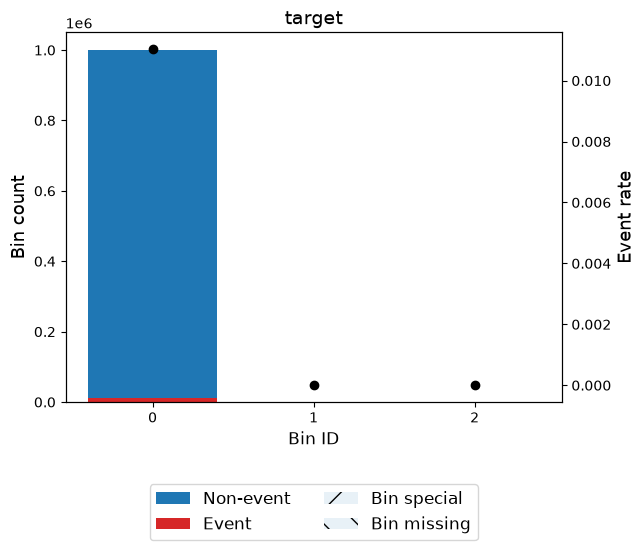

variable income
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.15)   157449     0.1574     156540    909      0.0058   
1       [0.15, 0.25)    69345     0.0693      68907    438      0.0063   
2       [0.25, 0.35)    50833     0.0508      50495    338      0.0066   
3       [0.35, 0.45)    81364     0.0814      80767    597      0.0073   
4       [0.45, 0.55)    55858     0.0559      55414    444      0.0079   
5       [0.55, 0.65)   111973     0.1120     110990    983      0.0088   
6       [0.65, 0.75)   105109     0.1051     104182    927      0.0088   
7       [0.75, 0.85)   146650     0.1467     145048   1602      0.0109   
8        [0.85, inf)   221419     0.2214     216628   4791      0.0216   
9            Special        0     0.0000          0      0      0.0000   
10           Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.00

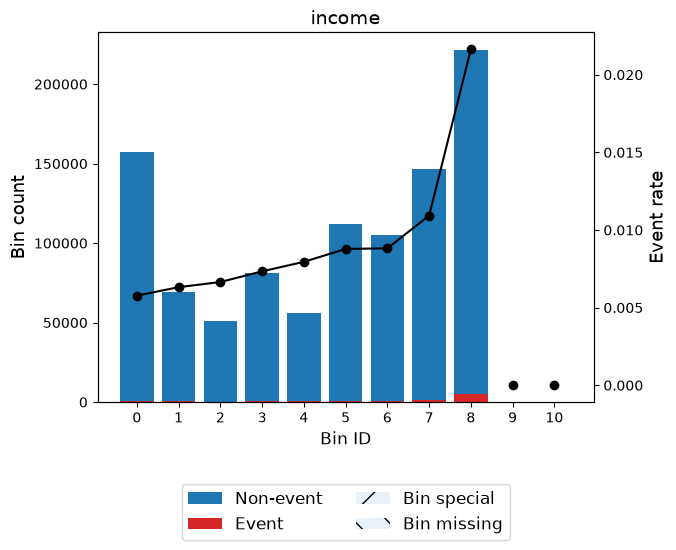

variable name_email_similarity
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.10)    90061     0.0901      88191   1870      0.0208   
1       [0.10, 0.17)    97970     0.0980      96104   1866      0.0190   
2       [0.17, 0.25)    88780     0.0888      87504   1276      0.0144   
3       [0.25, 0.35)    90460     0.0905      89410   1050      0.0116   
4       [0.35, 0.46)    92638     0.0926      91891    747      0.0081   
5       [0.46, 0.51)    55999     0.0560      55651    348      0.0062   
6       [0.51, 0.67)   149386     0.1494     148338   1048      0.0070   
7        [0.67, inf)   334706     0.3347     331882   2824      0.0084   
8            Special        0     0.0000          0      0      0.0000   
9            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV 

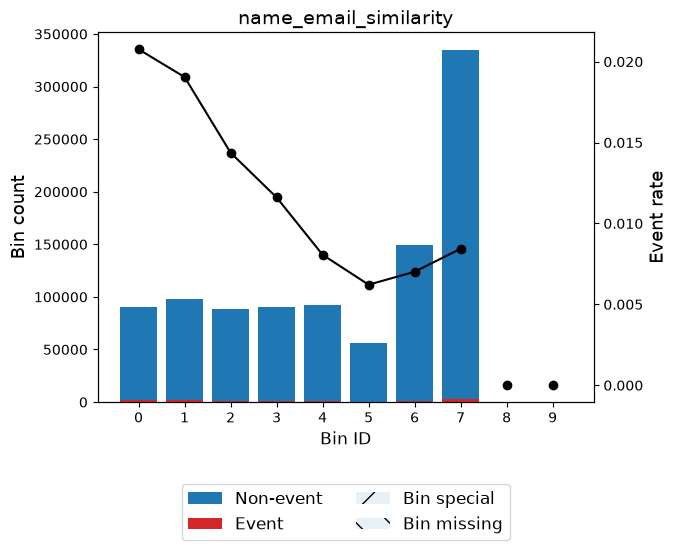

variable prev_address_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 2.00)   712920     0.7129     702786  10134      0.0142   
1        [2.00, 26.50)    81440     0.0814      81260    180      0.0022   
2       [26.50, 90.50)   145963     0.1460     145568    395      0.0027   
3         [90.50, inf)    59677     0.0597      59357    320      0.0054   
4              Special        0     0.0000          0      0      0.0000   
5              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.2570 0.0535 0.0067  
1       1.6163 0.1064 0.0120  
2       1.4134 0.1574 0.0182  
3       0.7269 0.0225 0.0028  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.3399 0.0396  


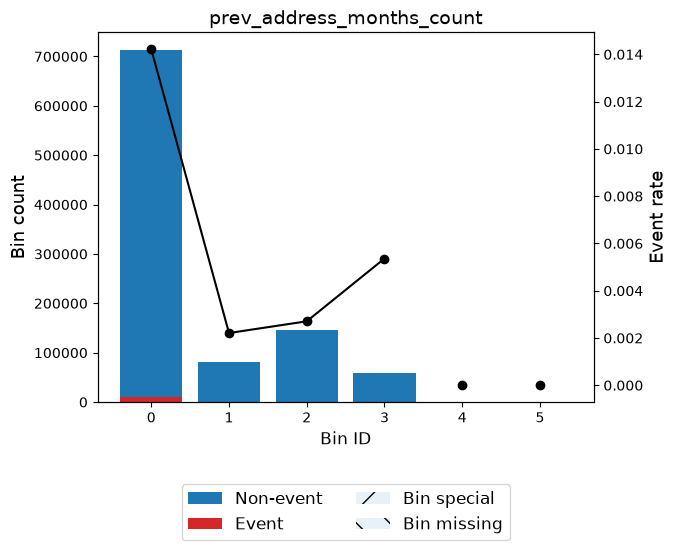

variable current_address_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 6.50)    94935     0.0949      94586    349      0.0037   
1        [6.50, 11.50)    76774     0.0768      76539    235      0.0031   
2       [11.50, 17.50)    61759     0.0618      61545    214      0.0035   
3       [17.50, 31.50)    93305     0.0933      92853    452      0.0048   
4       [31.50, 38.50)    61456     0.0615      61068    388      0.0063   
5       [38.50, 46.50)    67875     0.0679      67314    561      0.0083   
6       [46.50, 57.50)    74331     0.0743      73374    957      0.0129   
7         [57.50, inf)   469565     0.4696     461692   7873      0.0168   
8              Special        0     0.0000          0      0      0.0000   
9              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.

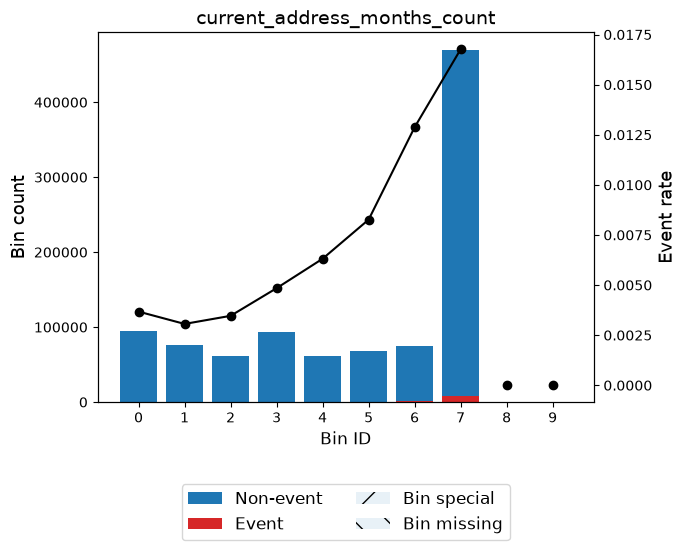

variable customer_age
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 25.00)   266842     0.2668     265563   1279      0.0048   
1       [25.00, 35.00)   311433     0.3114     308844   2589      0.0083   
2       [35.00, 45.00)   238712     0.2387     235836   2876      0.0120   
3         [45.00, inf)   183013     0.1830     178728   4285      0.0234   
4              Special        0     0.0000          0      0      0.0000   
5              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.8396 0.1281 0.0156  
1       0.2854 0.0221 0.0028  
2      -0.0894 0.0020 0.0002  
3      -0.7654 0.1590 0.0194  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.3113 0.0380  


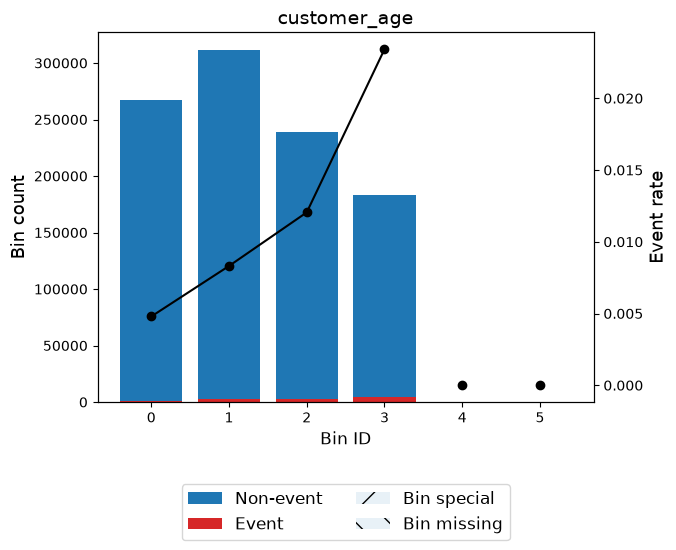

variable days_since_request
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.00)    55075     0.0551      54295    780      0.0142   
1       [0.00, 0.01)   173686     0.1737     171400   2286      0.0132   
2       [0.01, 0.01)   120324     0.1203     118889   1435      0.0119   
3       [0.01, 0.02)   204987     0.2050     202622   2365      0.0115   
4       [0.02, 0.02)    88208     0.0882      87297    911      0.0103   
5       [0.02, 0.02)    53030     0.0530      52525    505      0.0095   
6       [0.02, 0.03)   113045     0.1130     112092    953      0.0084   
7       [0.03, 0.37)    99064     0.0991      98491    573      0.0058   
8        [0.37, inf)    92581     0.0926      91360   1221      0.0132   
9            Special        0     0.0000          0      0      0.0000   
10           Missing        0     0.0000          0      0      0.0000   
Totals                1000

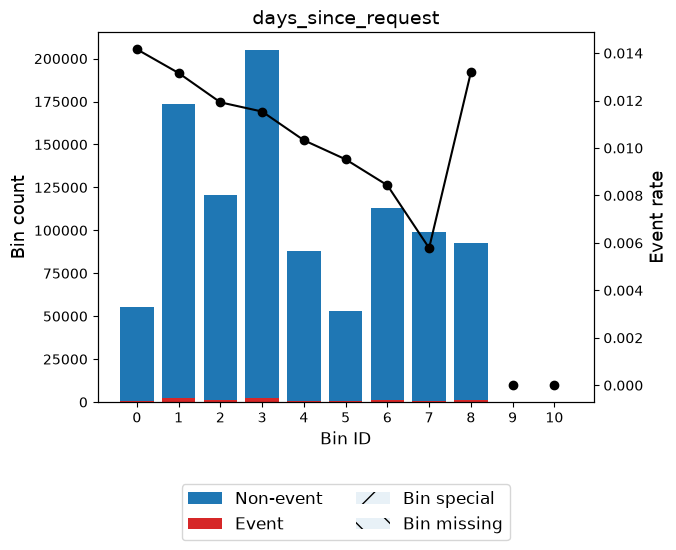

variable intended_balcon_amount
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 0.07)   743314     0.7433     733549   9765      0.0131   
1        [0.07, 19.69)    59794     0.0598      59558    236      0.0039   
2       [19.69, 50.39)   146892     0.1469     146182    710      0.0048   
3         [50.39, inf)    50000     0.0500      49682    318      0.0064   
4              Special        0     0.0000          0      0      0.0000   
5              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.1770 0.0254 0.0032  
1       1.0347 0.0402 0.0048  
2       0.8312 0.0694 0.0084  
3       0.5552 0.0119 0.0015  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.1468 0.0179  


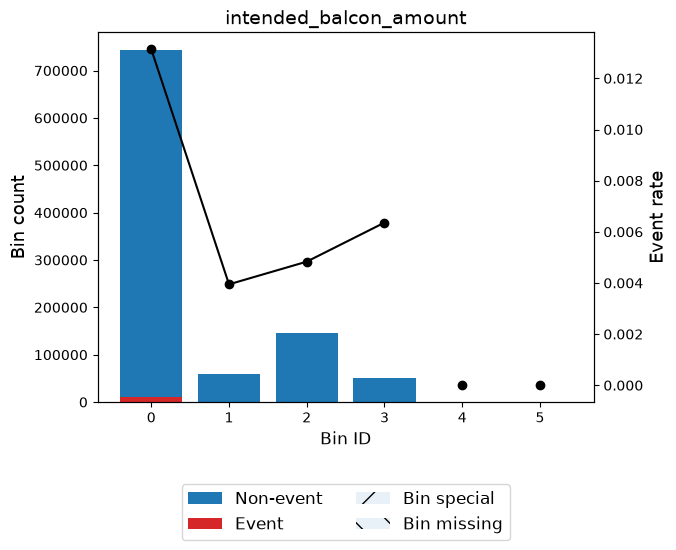

variable zip_count_4w
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0           (-inf, 942.50)   283097     0.2831     280075   3022      0.0107   
1        [942.50, 1045.50)    73796     0.0738      73058    738      0.0100   
2       [1045.50, 1124.50)    55520     0.0555      55015    505      0.0091   
3       [1124.50, 1275.50)    94952     0.0950      94003    949      0.0100   
4       [1275.50, 1513.50)   108148     0.1081     106973   1175      0.0109   
5       [1513.50, 1871.50)   117119     0.1171     115759   1360      0.0116   
6           [1871.50, inf)   267368     0.2674     264088   3280      0.0123   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       

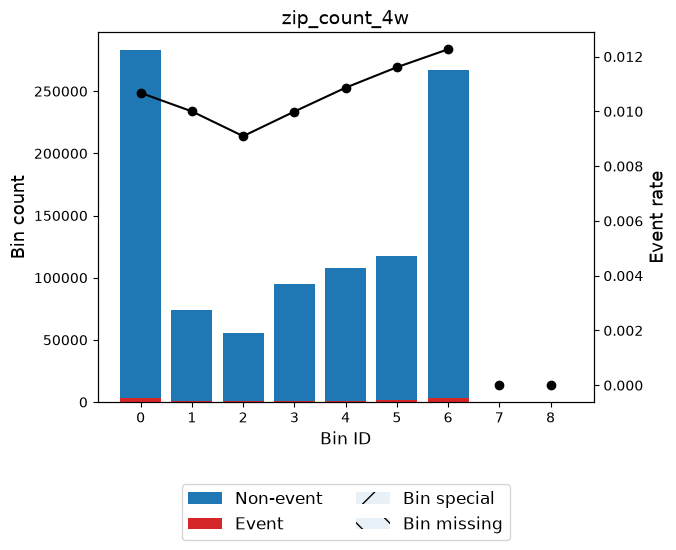

variable velocity_6h
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 1312.93)    53596     0.0536      52760    836      0.0156   
1       [1312.93, 2679.78)   115123     0.1151     113430   1693      0.0147   
2       [2679.78, 5778.84)   387772     0.3878     383474   4298      0.0111   
3       [5778.84, 7493.96)   175574     0.1756     173763   1811      0.0103   
4       [7493.96, 8105.80)    60009     0.0600      59403    606      0.0101   
5       [8105.80, 9696.26)   110839     0.1108     109750   1089      0.0098   
6           [9696.26, inf)    97087     0.0971      96391    696      0.0072   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0

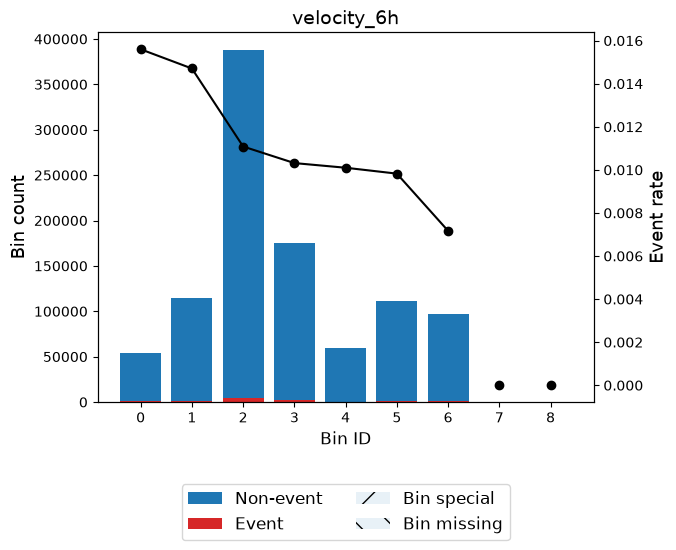

variable velocity_24h
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 3064.48)   133781     0.1338     131857   1924      0.0144   
1       [3064.48, 3383.27)    70158     0.0702      69332    826      0.0118   
2       [3383.27, 5141.45)   406552     0.4066     402063   4489      0.0110   
3       [5141.45, 5959.54)   180962     0.1810     179017   1945      0.0107   
4       [5959.54, 6490.21)    71365     0.0714      70649    716      0.0100   
5       [6490.21, 7113.55)    67590     0.0676      67055    535      0.0079   
6           [7113.55, inf)    69592     0.0696      68998    594      0.0085   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -

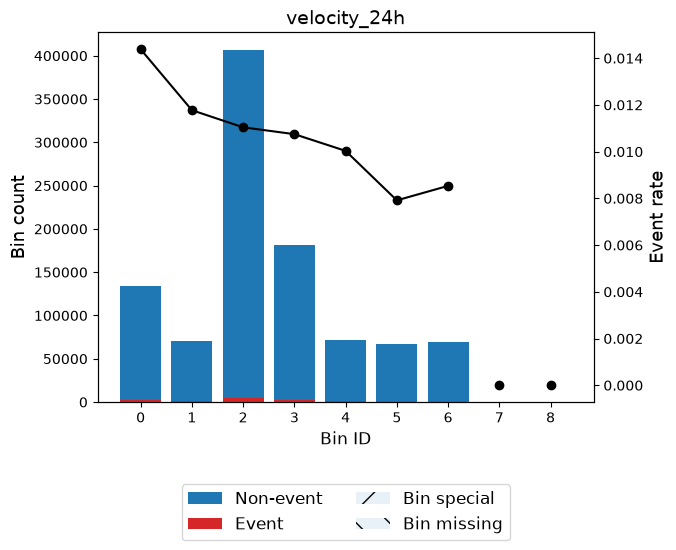

variable velocity_4w
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 4081.97)   149179     0.1492     146954   2225      0.0149   
1       [4081.97, 4212.06)    50553     0.0506      49821    732      0.0145   
2       [4212.06, 4271.37)    53224     0.0532      52632    592      0.0111   
3       [4271.37, 5043.04)   305257     0.3053     301932   3325      0.0109   
4       [5043.04, 5582.10)   248568     0.2486     246347   2221      0.0089   
5       [5582.10, 5853.65)    57892     0.0579      57506    386      0.0067   
6       [5853.65, 6457.01)    85227     0.0852      84340    887      0.0104   
7           [6457.01, inf)    50100     0.0501      49439    661      0.0132   
8                  Special        0     0.0000          0      0      0.0000   
9                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1

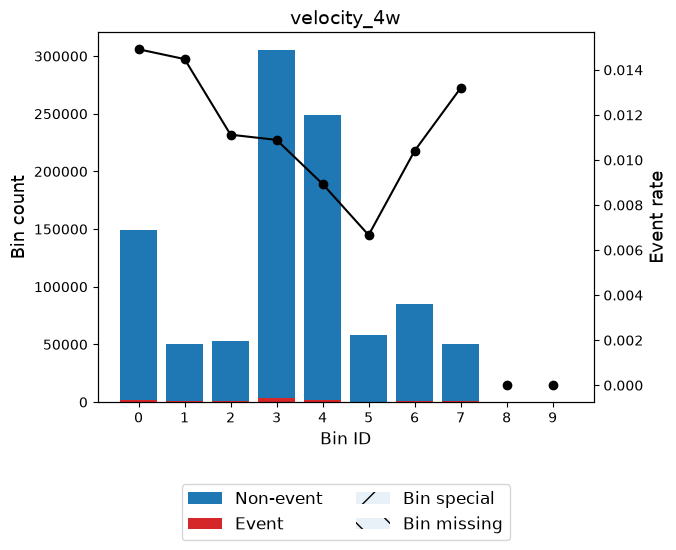

variable bank_branch_count_8w
---------------------------------------------------------
                      Bin    Count  Count (%)  Non-event  Event  Event rate  \
0            (-inf, 0.50)   144376     0.1444     141811   2565      0.0178   
1            [0.50, 1.50)   149028     0.1490     146633   2395      0.0161   
2            [1.50, 2.50)    57792     0.0578      57063    729      0.0126   
3           [2.50, 16.50)   338035     0.3380     335077   2958      0.0088   
4         [16.50, 312.50)   167108     0.1671     165731   1377      0.0082   
5       [312.50, 1397.50)    84646     0.0846      84193    453      0.0054   
6          [1397.50, inf)    59015     0.0590      58463    552      0.0094   
7                 Special        0     0.0000          0      0      0.0000   
8                 Missing        0     0.0000          0      0      0.0000   
Totals                     1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.4

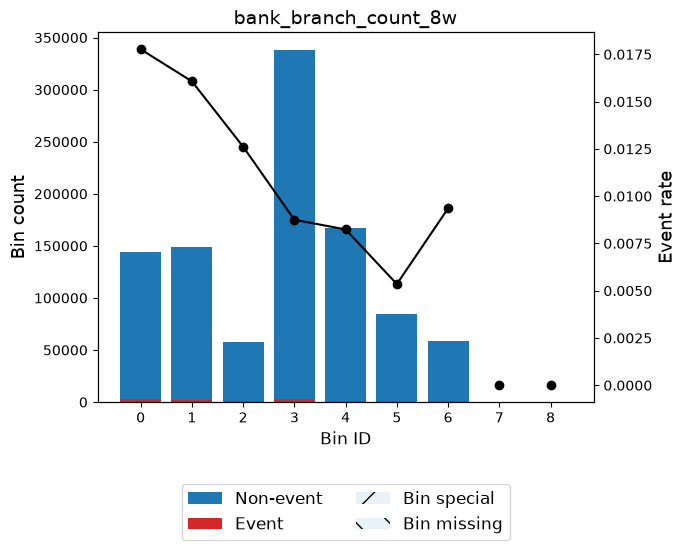

variable date_of_birth_distinct_emails_4w
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 2.50)    51430     0.0514      49606   1824      0.0355   
1         [2.50, 4.50)   106776     0.1068     105164   1612      0.0151   
2         [4.50, 8.50)   321708     0.3217     317927   3781      0.0118   
3         [8.50, 9.50)    67341     0.0673      66585    756      0.0112   
4        [9.50, 10.50)    62681     0.0627      62135    546      0.0087   
5       [10.50, 12.50)   125865     0.1259     124995    870      0.0069   
6       [12.50, 13.50)    60773     0.0608      60384    389      0.0064   
7         [13.50, inf)   203426     0.2034     202175   1251      0.0061   
8              Special        0     0.0000          0      0      0.0000   
9              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029    

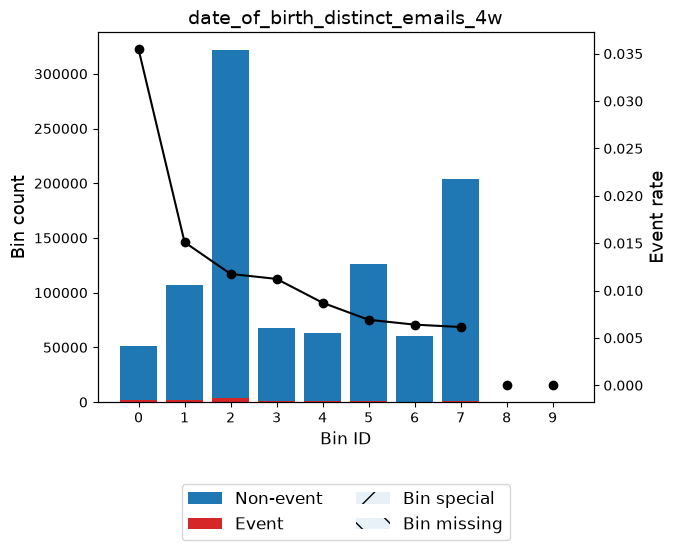

variable credit_risk_score
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 45.50)    92595     0.0926      92117    478      0.0052   
1        [45.50, 127.50)   438424     0.4384     435536   2888      0.0066   
2       [127.50, 137.50)    54379     0.0544      54009    370      0.0068   
3       [137.50, 157.50)    86374     0.0864      85578    796      0.0092   
4       [157.50, 173.50)    61281     0.0613      60537    744      0.0121   
5       [173.50, 198.50)    89811     0.0898      88659   1152      0.0128   
6       [198.50, 219.50)    62012     0.0620      61044    968      0.0156   
7       [219.50, 250.50)    58755     0.0588      57529   1226      0.0209   
8          [250.50, inf)    56369     0.0564      53962   2407      0.0427   
9                Special        0     0.0000          0      0      0.0000   
10               Missing        0     0.0000          0  

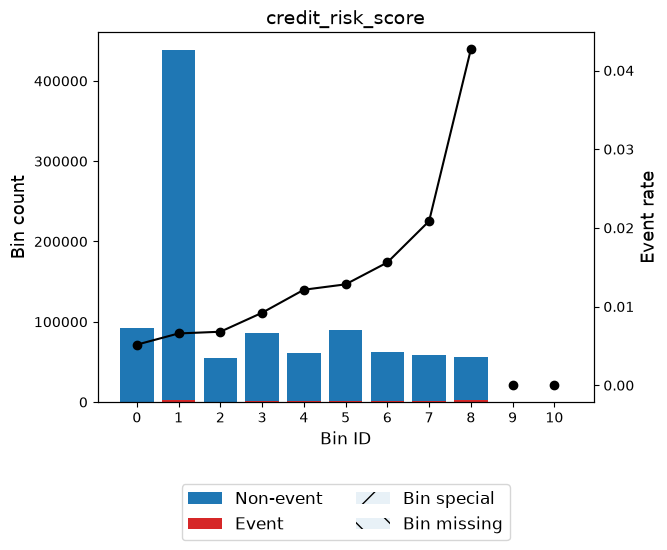

variable email_is_free
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   470114     0.4701     466376   3738      0.0080   
1        [0.50, inf)   529886     0.5299     522595   7291      0.0138   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.3303 0.0438 0.0055  
1      -0.2240 0.0297 0.0037  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.0735 0.0092  


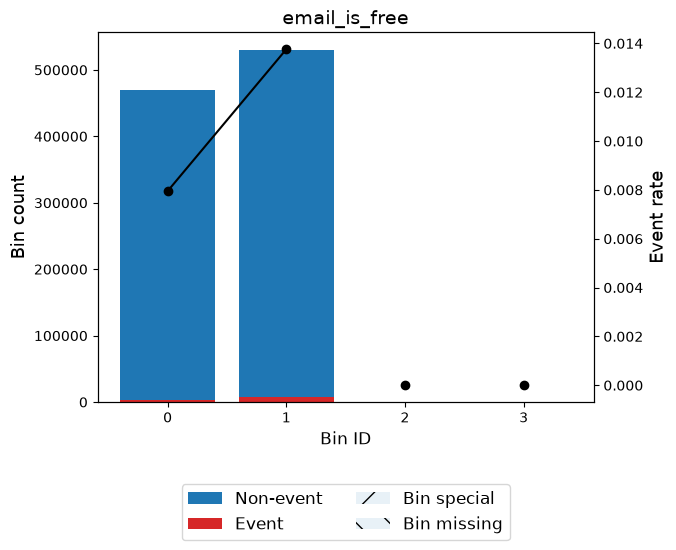

variable phone_home_valid
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   582923     0.5829     574685   8238      0.0141   
1        [0.50, inf)   417077     0.4171     414286   2791      0.0067   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.2511 0.0416 0.0052  
1       0.5040 0.0836 0.0103  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.1252 0.0155  


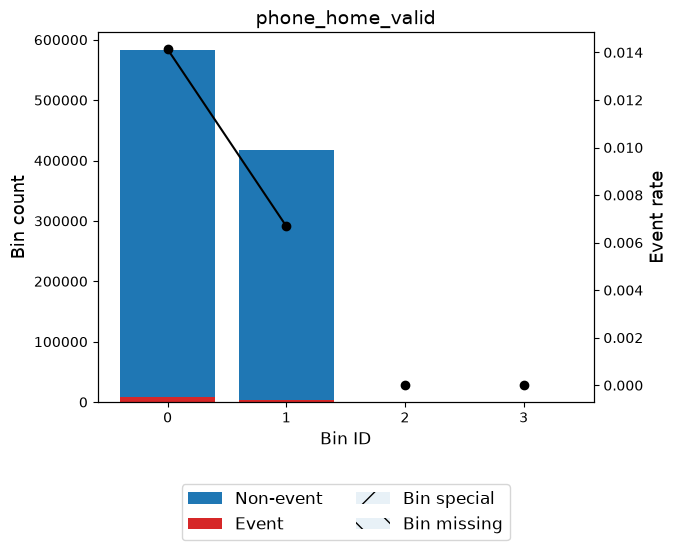

variable phone_mobile_valid
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   110324     0.1103     108676   1648      0.0149   
1        [0.50, inf)   889676     0.8897     880295   9381      0.0105   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.3073 0.0122 0.0015  
1       0.0454 0.0018 0.0002  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.0139 0.0017  


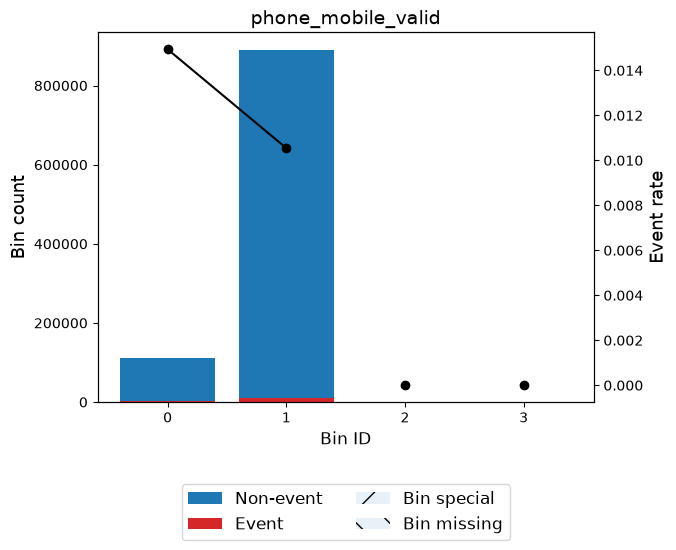

variable bank_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 0.00)   253635     0.2536     249495   4140      0.0163   
1         [0.00, 1.50)   194802     0.1948     193530   1272      0.0065   
2        [1.50, 23.50)   291630     0.2916     289248   2382      0.0082   
3       [23.50, 29.50)   163026     0.1630     161402   1624      0.0100   
4         [29.50, inf)    96907     0.0969      95296   1611      0.0166   
5              Special        0     0.0000          0      0      0.0000   
6              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.3974 0.0489 0.0061  
1       0.5287 0.0425 0.0052  
2       0.3032 0.0232 0.0029  
3       0.1029 0.0016 0.0002  
4      -0.4160 0.0207 0.0026  
5       0.0000 0.0000 0.0000  
6       0.000

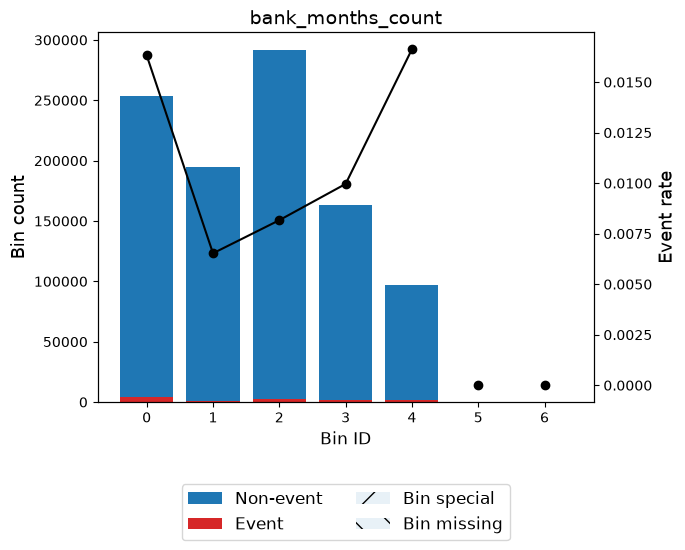

variable has_other_cards
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   777012     0.7770     766914  10098      0.0130   
1        [0.50, inf)   222988     0.2230     222057    931      0.0042   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.1661 0.0233 0.0029  
1       0.9783 0.1371 0.0165  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.1604 0.0194  


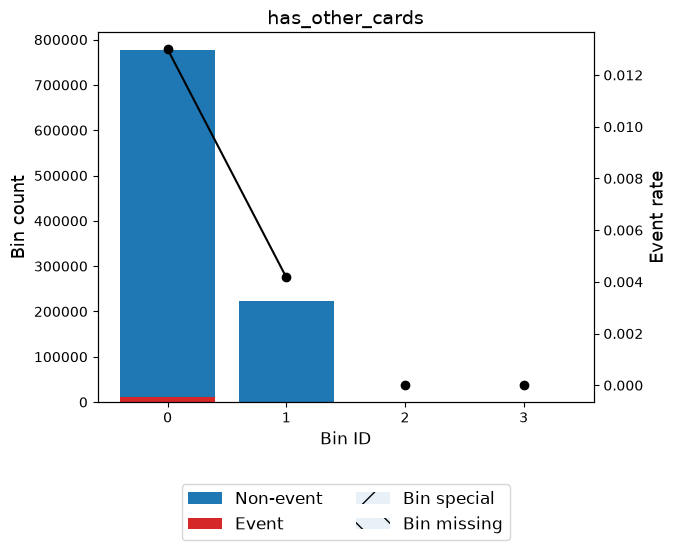

variable proposed_credit_limit
---------------------------------------------------------
                      Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 350.00)   614624     0.6146     610198   4426      0.0072   
1        [350.00, 750.00)   143634     0.1436     142132   1502      0.0105   
2       [750.00, 1250.00)    89462     0.0895      88422   1040      0.0116   
3          [1250.00, inf)   152280     0.1523     148219   4061      0.0267   
4                 Special        0     0.0000          0      0      0.0000   
5                 Missing        0     0.0000          0      0      0.0000   
Totals                     1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.4302 0.0928 0.0115  
1       0.0538 0.0004 0.0001  
2      -0.0532 0.0003 0.0000  
3      -0.8989 0.1963 0.0237  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.2897 0.0353  


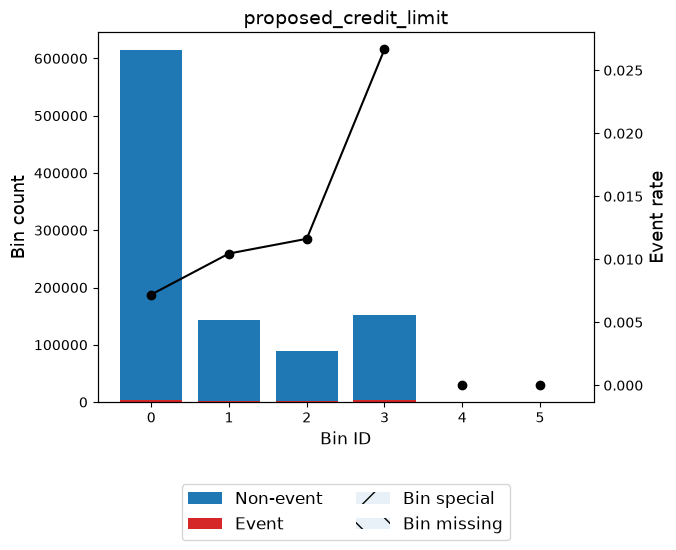

variable foreign_request
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


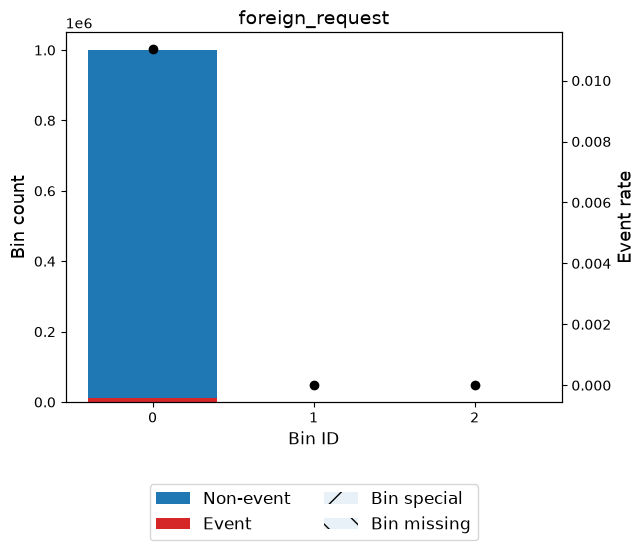

variable session_length_in_minutes
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 8.02)   710424     0.7104     702458   7966      0.0112   
1         [8.02, 9.61)    67905     0.0679      67177    728      0.0107   
2        [9.61, 11.64)    55634     0.0556      55122    512      0.0092   
3       [11.64, 15.27)    62262     0.0623      61788    474      0.0076   
4       [15.27, 21.58)    53243     0.0532      52731    512      0.0096   
5         [21.58, inf)    50532     0.0505      49695    837      0.0166   
6              Special        0     0.0000          0      0      0.0000   
7              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.0167 0.0002 0.0000  
1       0.0286 0.0001 0.0000  
2       0.1828 0.0017 0.0002  
3       0.3741 0.0073 

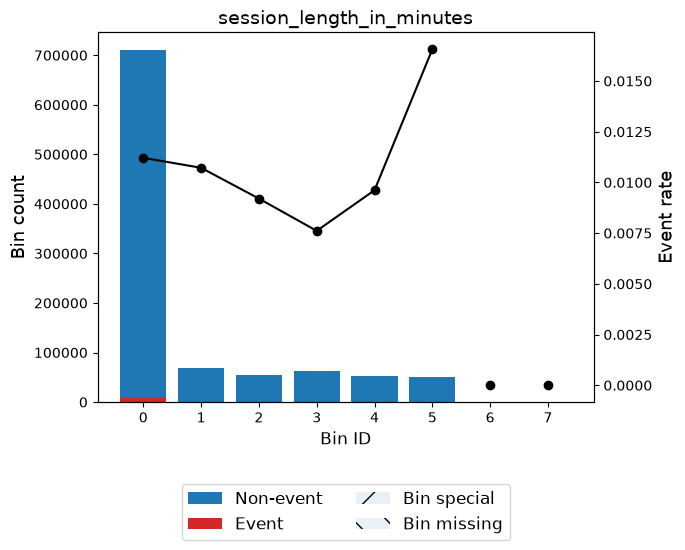

variable keep_alive_session
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   423053     0.4231     415792   7261      0.0172   
1        [0.50, inf)   576947     0.5769     573179   3768      0.0065   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.4485 0.1067 0.0132  
1       0.5285 0.1257 0.0155  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.2325 0.0288  


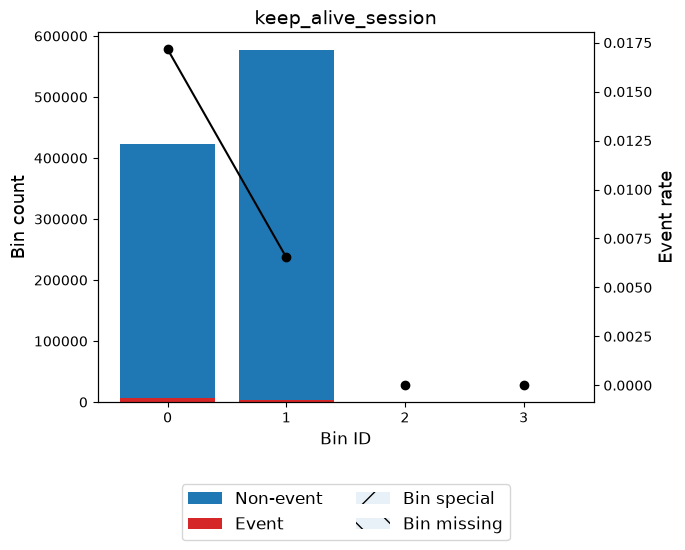

variable device_distinct_emails_8w
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


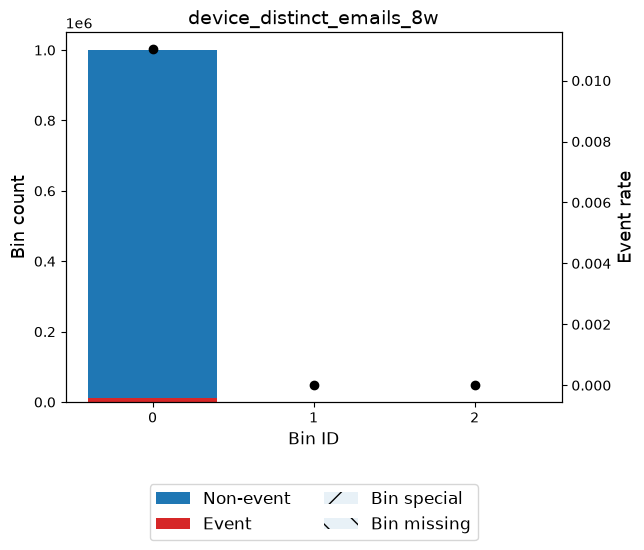

variable device_fraud_count
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


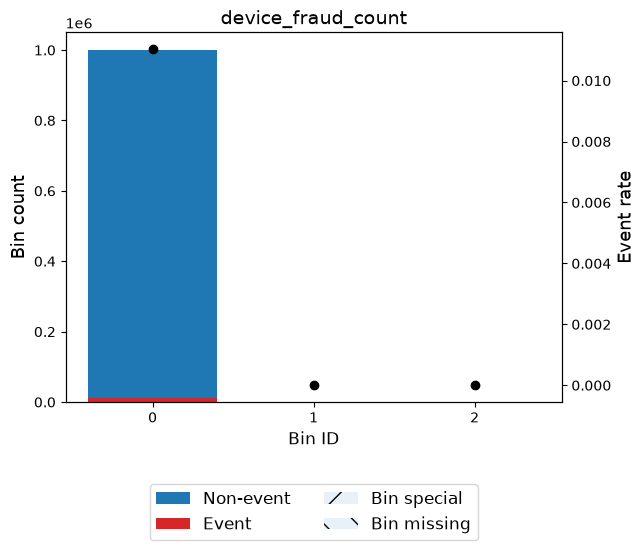

In [19]:
df_result = plot_analisis(df_numeric, 'numerical', columnas_numericas, 'target', 0.09)

In [20]:
# Configurar Pandas para una mejor visualización
pd.set_option('display.max_rows', None)  # Mostrar todas las filas
pd.set_option('display.max_columns', None)  # Mostrar todas las columnas
pd.set_option('display.width', 1000)  # Ajustar el ancho de la visualización
pd.set_option('display.max_colwidth', 50)  # Limitar el ancho de las celdas

In [21]:
# Ver el DataFrame completo
print(df_result)

                               index        IV
0                  credit_risk_score  0.417043
1       current_address_months_count  0.363718
2          prev_address_months_count  0.339891
3                       customer_age  0.311268
4              proposed_credit_limit  0.289707
5                             income  0.250911
6   date_of_birth_distinct_emails_4w  0.244854
7                 keep_alive_session  0.232451
8              name_email_similarity  0.167995
9                    has_other_cards  0.160352
10            intended_balcon_amount  0.146844
11                 bank_months_count  0.136918
12              bank_branch_count_8w  0.133252
13                  phone_home_valid  0.125229


## IV - Woe Categorico

In [22]:
# Seleccionamos categóricas

# Crear un nuevo dataframe con solo las columnas categóricas
df_categoricals = df_data.select_dtypes(include=['object', 'category'])

# Obtener la lista de columnas categóricas
columnas_categoricas = df_categoricals.columns.tolist()

# Agregar la variable target al DataFrame df_categoricals
df_categoricals['target'] = df_data['target']

# Columnas a excluir
columnas_a_excluir = []
#'periodo',id_cliente_persona', 'id_resppago', 'tip_documento'

# Excluir las columnas no deseadas del DataFrame df_categoricals
df_cat = df_categoricals.drop(columns=columnas_a_excluir)

# Actualizar la lista de columnas categóricas para excluir las columnas no deseadas
columnas_categoricas = [col for col in columnas_categoricas if col not in columnas_a_excluir]

# Verificar el resultado
print("Columnas en df_cat después de excluir las no deseadas:")
print(df_cat.columns.tolist())

Columnas en df_cat después de excluir las no deseadas:
['payment_type', 'employment_status', 'housing_status', 'source', 'device_os', 'period', 'target']


variable payment_type
---------------------------------------------------------
             Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [AE, AA]   258538     0.2585     257173   1365      0.0053  0.7425 0.1012 0.0124
1           [AD]   118837     0.1188     117551   1286      0.0108  0.0192 0.0000 0.0000
2           [AB]   370554     0.3706     366385   4169      0.0113 -0.0201 0.0002 0.0000
3           [AC]   252071     0.2521     247862   4209      0.0167 -0.4205 0.0551 0.0068
4        Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5        Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals            1000000     1.0000     988971  11029      0.0110         0.1565 0.0192


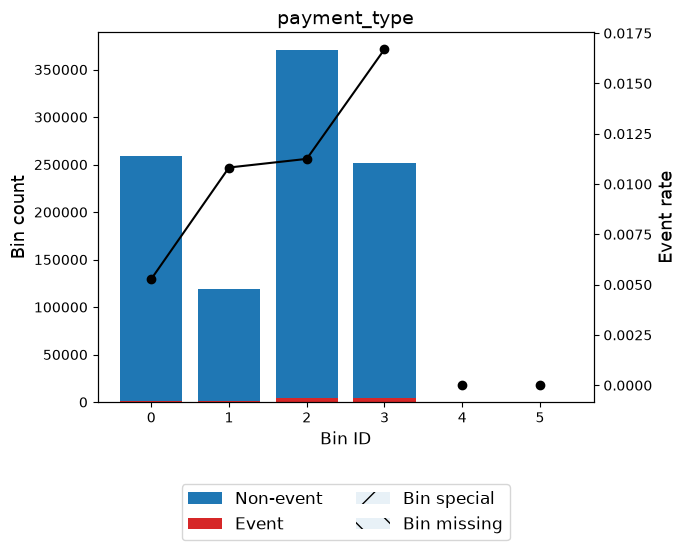

variable employment_status
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [CF, CE, CD]    93249     0.0932      93011    238      0.0026  1.4721 0.1067 0.0122
1               [CB]   138288     0.1383     137335    953      0.0069  0.4744 0.0249 0.0031
2       [CA, CG, CC]   768463     0.7685     758625   9838      0.0128 -0.1509 0.0188 0.0024
3            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
4            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.1504 0.0177


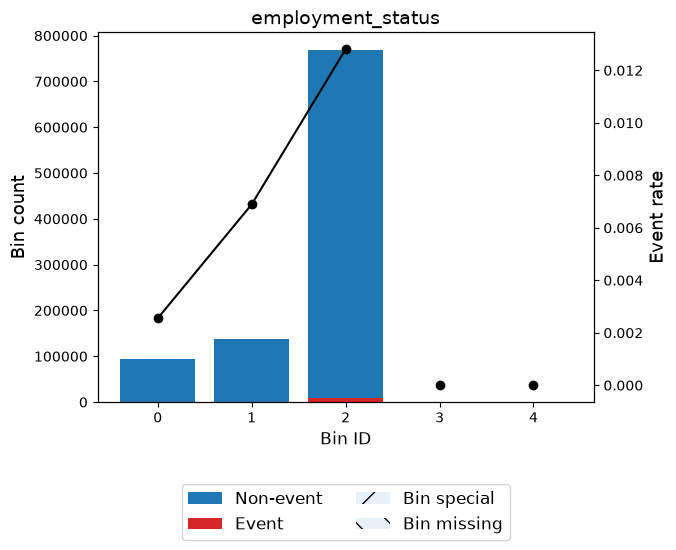

variable housing_status
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [BE, BG, BF]   171056     0.1711     170466    590      0.0034  1.1700 0.1391 0.0165
1               [BB]   260965     0.2610     259397   1568      0.0060  0.6124 0.0736 0.0091
2           [BC, BD]   398304     0.3983     395790   2514      0.0063  0.5629 0.0970 0.0120
3               [BA]   169675     0.1697     163318   6357      0.0375 -1.2500 0.5141 0.0604
4            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.8237 0.0978


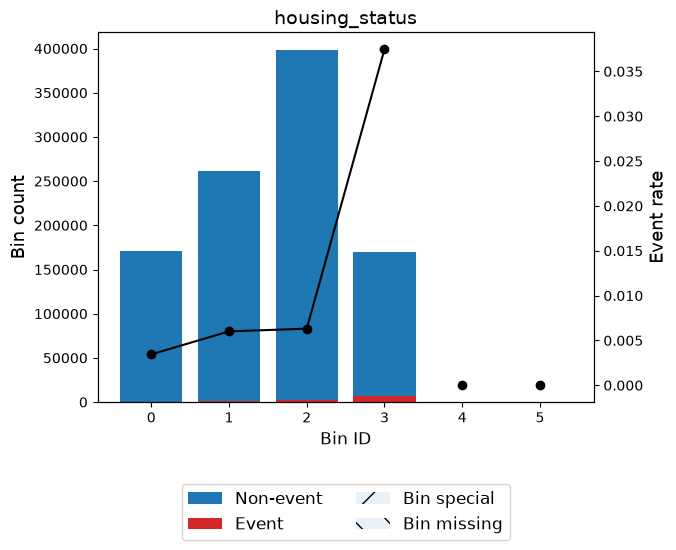

variable source
---------------------------------------------------------
                        Bin    Count  Count (%)  Non-event  Event  Event rate    WoE     IV     JS
0       [INTERNET, TELEAPP]  1000000     1.0000     988971  11029      0.0110 0.0000 0.0000 0.0000
1                   Special        0     0.0000          0      0      0.0000 0.0000 0.0000 0.0000
2                   Missing        0     0.0000          0      0      0.0000 0.0000 0.0000 0.0000
Totals                       1000000     1.0000     988971  11029      0.0110        0.0000 0.0000


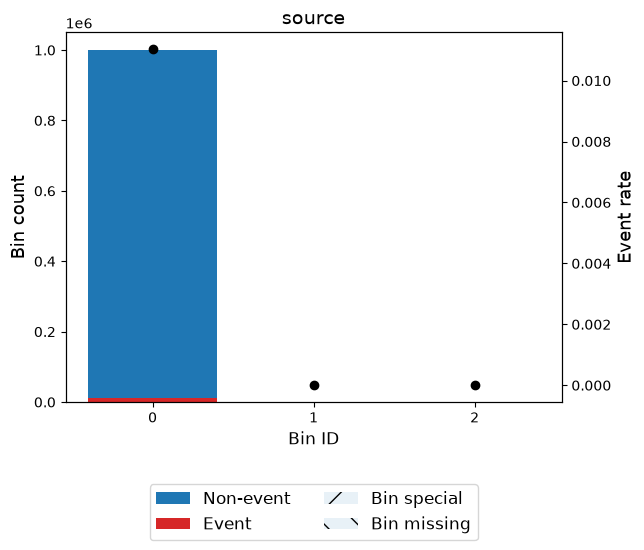

variable device_os
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0                [linux]   332712     0.3327     330997   1715      0.0052  0.7666 0.1374 0.0168
1                [other]   342728     0.3427     340754   1974      0.0058  0.6550 0.1084 0.0133
2       [x11, macintosh]    61054     0.0611      60221    833      0.0136 -0.2154 0.0032 0.0004
3              [windows]   263506     0.2635     256999   6507      0.0247 -0.8199 0.2707 0.0329
4                Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5                Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                    1000000     1.0000     988971  11029      0.0110         0.5196 0.0634


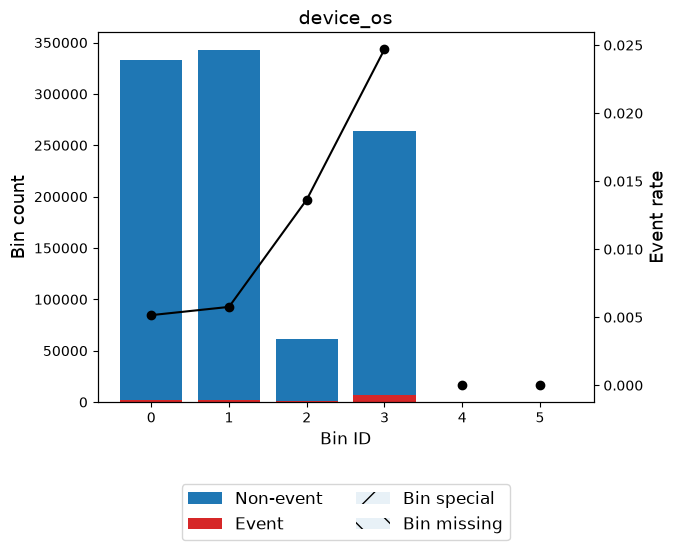

variable period
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [2024-03-01]   136979     0.1370     135781   1198      0.0087  0.2343 0.0067 0.0008
1       [2024-04-01]   150936     0.1509     149544   1392      0.0092  0.1807 0.0045 0.0006
2       [2024-02-01]   127620     0.1276     126422   1198      0.0094  0.1628 0.0031 0.0004
3       [2024-01-01]   132440     0.1324     130940   1500      0.0113 -0.0269 0.0001 0.0000
4       [2024-05-01]   127691     0.1277     126239   1452      0.0114 -0.0309 0.0001 0.0000
5       [2024-06-01]   119323     0.1193     117912   1411      0.0118 -0.0705 0.0006 0.0001
6       [2024-07-01]   108168     0.1082     106718   1450      0.0134 -0.1975 0.0047 0.0006
7       [2024-08-01]    96843     0.0968      95415   1428      0.0147 -0.2942 0.0097 0.0012
8            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0

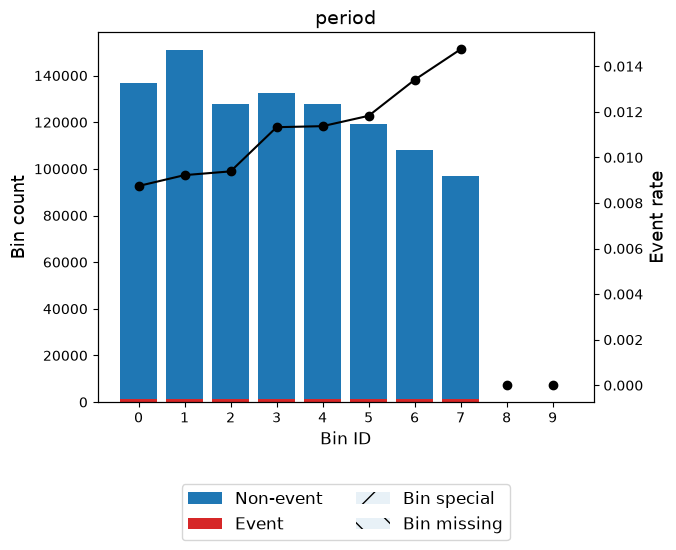

In [23]:
# Ejecutar el análisis con el umbral de 0.03
df_result_cat = plot_analisis(df_cat, 'categorical', columnas_categoricas, 'target', 0.05)

In [35]:
# Ver el DataFrame completo
print(df_result_cat)

               index        IV
0     housing_status  0.823668
1          device_os  0.519638
2       payment_type  0.156460
3  employment_status  0.150415


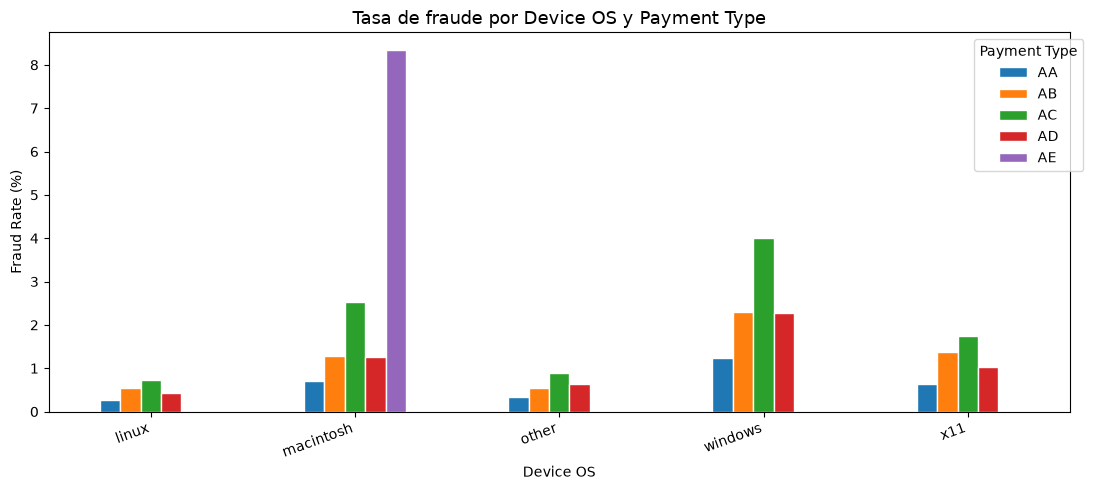

In [37]:
ct = (
    df_data
    .groupby(["device_os", "payment_type"])["target"]
    .mean()
    .mul(100)
    .unstack()
)

ct.plot(
    kind="bar",
    figsize=(11,5),
    edgecolor="white"
)

plt.title("Tasa de fraude por Device OS y Payment Type", fontsize=13)
plt.xlabel("Device OS")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Payment Type", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

## IV - WoE NUEVAS VARS

In [38]:
import numpy as np

# ============================================================
# Copia para no modificar el dataframe original
# ============================================================

df_feat = df_data.copy()

# ============================================================
# 1. Address Stability
# ============================================================

df_feat["address_total_history"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    +
    df_feat["prev_address_months_count"].clip(lower=0)
)

df_feat["address_stability_ratio"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    /
    (
        df_feat["prev_address_months_count"].clip(lower=0)
        + 1
    )
)

# ============================================================
# 2. Digital Identity Score
# ============================================================

df_feat["digital_identity_score"] = (
    df_feat["phone_home_valid"].astype(int)
    +
    df_feat["phone_mobile_valid"].astype(int)
    +
    (~df_feat["email_is_free"]).astype(int)
)

# ============================================================
# 3. Velocity Ratio
# ============================================================

df_feat["velocity_ratio_6h_24h"] = (
    df_feat["velocity_6h"]
    /
    (df_feat["velocity_24h"] + 1)
)

df_feat["velocity_ratio_24h_4w"] = (
    df_feat["velocity_24h"]
    /
    (df_feat["velocity_4w"] + 1)
)

# ============================================================
# 4. Device Trust
# ============================================================

df_feat["device_trust_score"] = (
    df_feat["device_distinct_emails_8w"]
    +
    5 * df_feat["device_fraud_count"]
    +
    (1 - df_feat["keep_alive_session"])
)

# ============================================================
# 5. Email Risk
# ============================================================

df_feat["email_risk_score"] = (
    (1 - df_feat["name_email_similarity"])
    *
    (
        df_feat["date_of_birth_distinct_emails_4w"]
        + 1
    )
)

# ============================================================
# 6. Credit Consistency
# ============================================================

df_feat["credit_limit_income_ratio"] = (
    df_feat["proposed_credit_limit"]
    /
    (df_feat["income"] + 0.01)
)

df_feat["credit_risk_limit_ratio"] = (
    (
        df_feat["credit_risk_score"]
        - df_feat["credit_risk_score"].min()
        + 1
    )
    /
    (df_feat["proposed_credit_limit"] + 1)
)

# ============================================================
# 7. Customer Stability
# ============================================================

df_feat["customer_stability_score"] = (
    df_feat["bank_months_count"].clip(lower=0)
    +
    df_feat["current_address_months_count"].clip(lower=0)
)

# ============================================================
# 8. Contact Consistency
# ============================================================

df_feat["contact_consistency"] = (
    df_feat["phone_home_valid"].astype(int)
    *
    df_feat["phone_mobile_valid"].astype(int)
)

# ============================================================
# Variables nuevas
# ============================================================

nuevas_variables = [
    "address_total_history",
    "address_stability_ratio",
    "digital_identity_score",
    "velocity_ratio_6h_24h",
    "velocity_ratio_24h_4w",
    "device_trust_score",
    "email_risk_score",
    "credit_limit_income_ratio",
    "credit_risk_limit_ratio",
    "customer_stability_score",
    "contact_consistency"
]

In [39]:
df_numeric = df_feat[nuevas_variables + ["target"]]

columnas_numericas = nuevas_variables

C:\Users\Renzo\AppData\Local\Temp\ipykernel_32736\566123806.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[target] = data[target].astype(int)


variable address_total_history
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0          (-inf, 38.50)   224675     0.2247     223510   1165      0.0052  0.7606 0.0916 0.0112
1         [38.50, 45.50)    81129     0.0811      80586    543      0.0067  0.5038 0.0162 0.0020
2         [45.50, 51.50)    57019     0.0570      56518    501      0.0088  0.2296 0.0027 0.0003
3         [51.50, 60.50)    73737     0.0737      72932    805      0.0109  0.0103 0.0000 0.0000
4         [60.50, 68.50)    56271     0.0563      55620    651      0.0116 -0.0483 0.0001 0.0000
5         [68.50, 93.50)   106682     0.1067     105181   1501      0.0141 -0.2466 0.0073 0.0009
6        [93.50, 123.50)    98214     0.0982      96603   1611      0.0164 -0.4024 0.0195 0.0024
7       [123.50, 148.50)    59076     0.0591      58017   1059      0.0179 -0.4927 0.0184 0.0023
8       [148.50, 177.50)    52484     

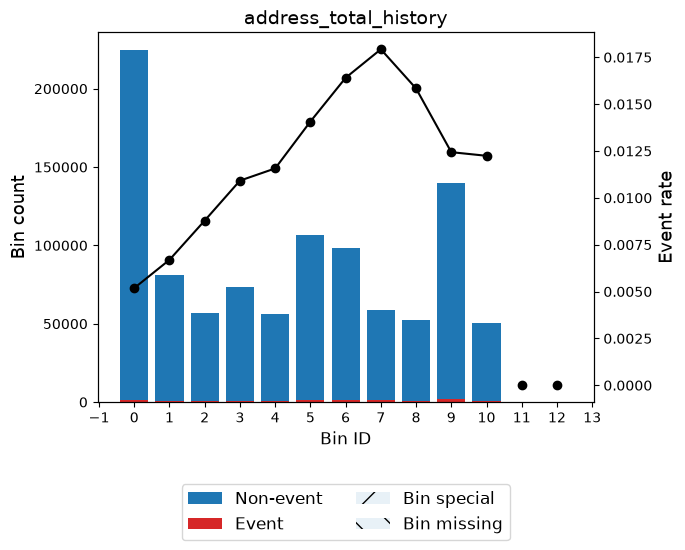

variable address_stability_ratio
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0         (-inf, 0.06)    50360     0.0504      50142    218      0.0043  0.9420 0.0291 0.0035
1         [0.06, 0.19)    73251     0.0733      73042    209      0.0029  1.3603 0.0747 0.0087
2         [0.19, 0.40)    64581     0.0646      64434    147      0.0023  1.5868 0.0822 0.0093
3         [0.40, 1.72)    78328     0.0783      78099    229      0.0029  1.3359 0.0778 0.0091
4        [1.72, 31.95)   102854     0.1029     102181    673      0.0065  0.5266 0.0223 0.0028
5       [31.95, 38.50)    51697     0.0517      51330    367      0.0071  0.4445 0.0083 0.0010
6       [38.50, 46.50)    61080     0.0611      60541    539      0.0088  0.2252 0.0028 0.0003
7       [46.50, 54.50)    50430     0.0504      49755    675      0.0134 -0.1960 0.0021 0.0003
8       [54.50, 65.50)    52624     0.0526      51767 

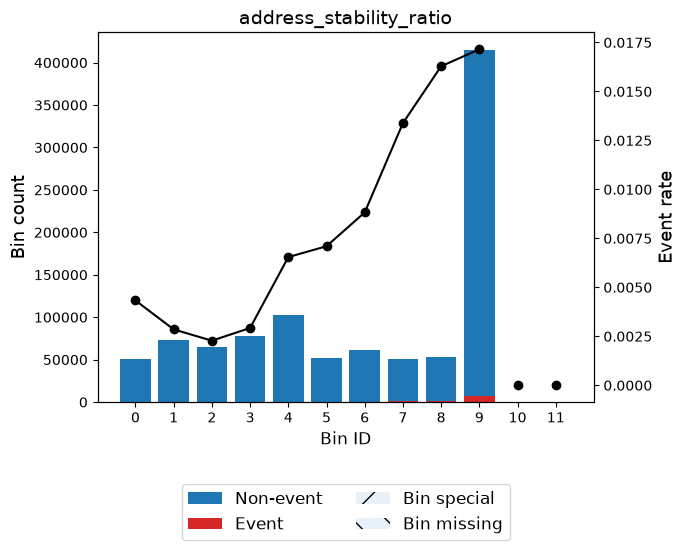

variable digital_identity_score
---------------------------------------------------------
                  Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, -0.50)   366395     0.3664     360047   6348      0.0173 -0.4580 0.0969 0.0120
1       [-0.50, 0.50)   479475     0.4795     475365   4110      0.0086  0.2545 0.0275 0.0034
2         [0.50, inf)   154130     0.1541     153559    571      0.0037  1.0983 0.1137 0.0135
3             Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
4             Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                 1000000     1.0000     988971  11029      0.0110         0.2380 0.0290


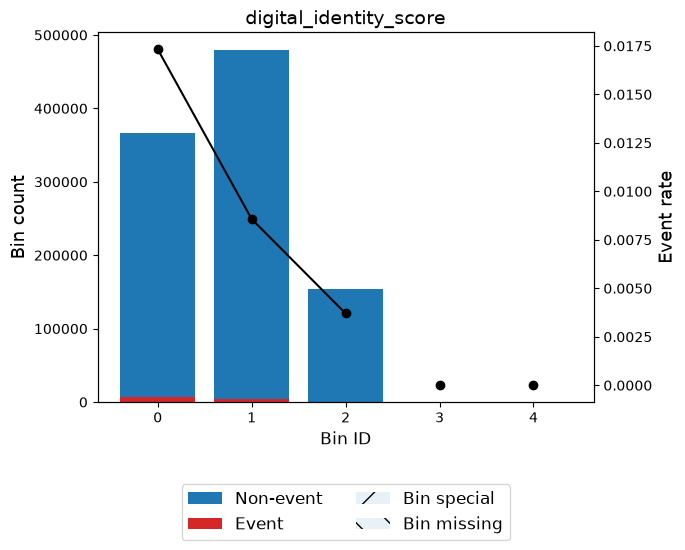

variable velocity_ratio_6h_24h
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, 0.38)    76737     0.0767      75619   1118      0.0146 -0.2820 0.0070 0.0009
1       [0.38, 0.54)    59658     0.0597      58862    796      0.0133 -0.1928 0.0024 0.0003
2       [0.54, 0.66)    50071     0.0501      49483    588      0.0117 -0.0635 0.0002 0.0000
3       [0.66, 1.14)   259331     0.2593     256356   2975      0.0115 -0.0398 0.0004 0.0001
4       [1.14, 1.61)   336670     0.3367     333116   3554      0.0106  0.0443 0.0006 0.0001
5       [1.61, 1.95)   138295     0.1383     136991   1304      0.0094  0.1583 0.0032 0.0004
6        [1.95, inf)    79238     0.0792      78544    694      0.0088  0.2328 0.0038 0.0005
7            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
8            Missing        0     0.0000          0      0      0.0000  0.

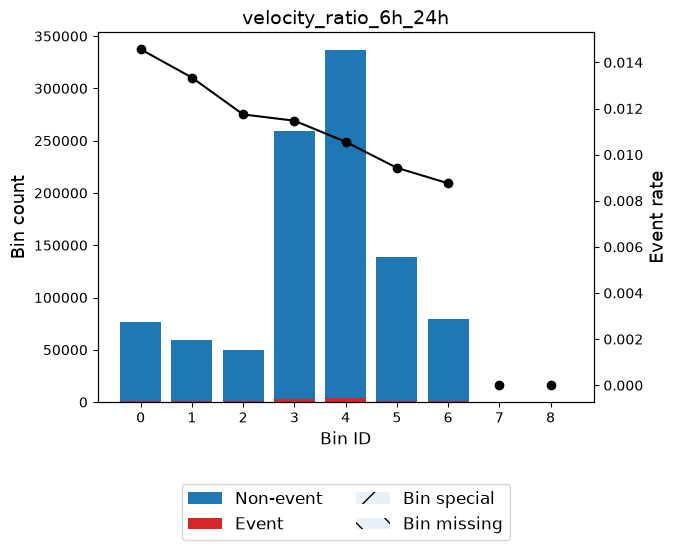

variable velocity_ratio_24h_4w
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, 0.63)    64592     0.0646      63749    843      0.0131 -0.1704 0.0020 0.0003
1       [0.63, 1.18)   721073     0.7211     712994   8079      0.0112 -0.0159 0.0002 0.0000
2       [1.18, 1.24)    55141     0.0551      54643    498      0.0090  0.2018 0.0020 0.0003
3       [1.24, 1.34)    77237     0.0772      76500    737      0.0095  0.1463 0.0015 0.0002
4        [1.34, inf)    81957     0.0820      81085    872      0.0106  0.0363 0.0001 0.0000
5            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
6            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.0059 0.0007


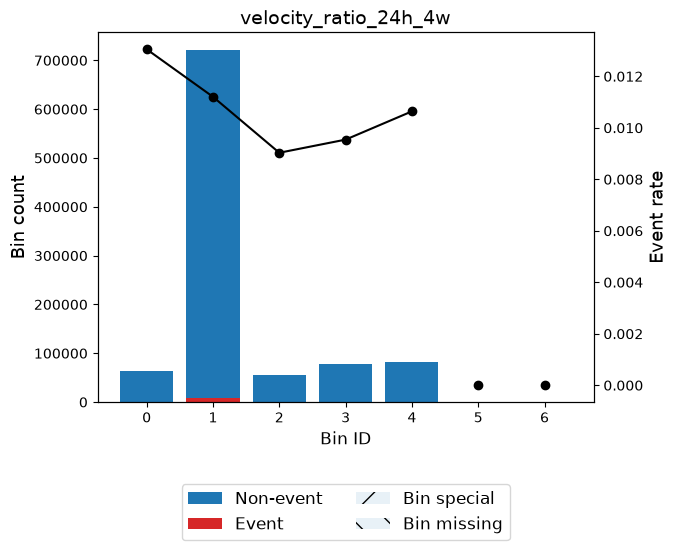

variable device_trust_score
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, 1.50)   574852     0.5749     571122   3730      0.0065  0.5351 0.1280 0.0158
1        [1.50, inf)   425148     0.4251     417849   7299      0.0172 -0.4488 0.1074 0.0133
2            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
3            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.2354 0.0291


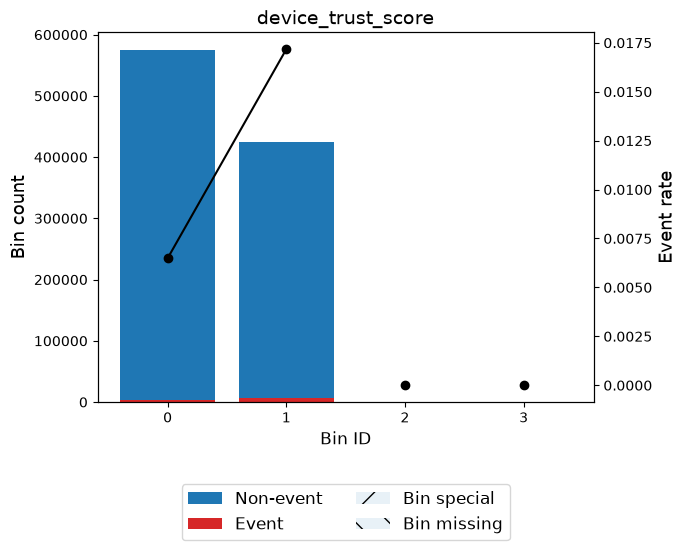

variable email_risk_score
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0         (-inf, 2.95)   366133     0.3661     361757   4376      0.0120 -0.0813 0.0025 0.0003
1        [2.95, 10.20)   504838     0.5048     499422   5416      0.0107  0.0280 0.0004 0.0000
2       [10.20, 13.52)    79029     0.0790      78302    727      0.0092  0.1833 0.0024 0.0003
3         [13.52, inf)    50000     0.0500      49490    510      0.0102  0.0790 0.0003 0.0000
4              Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5              Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                  1000000     1.0000     988971  11029      0.0110         0.0056 0.0007


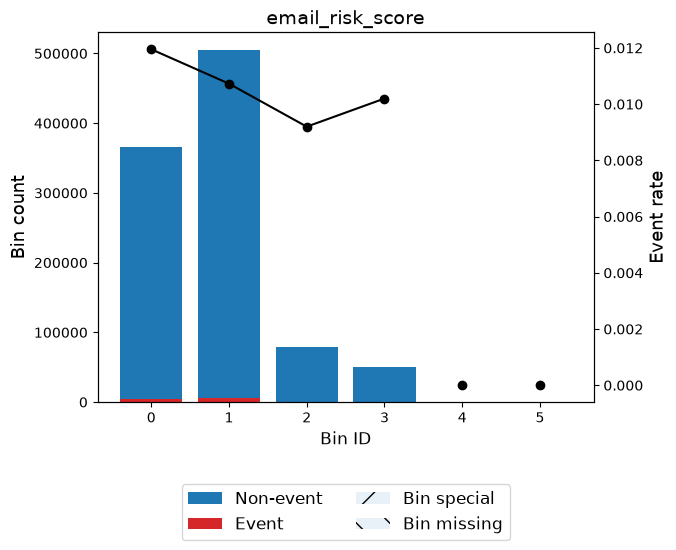

variable credit_limit_income_ratio
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0           (-inf, 225.27)   113266     0.1133     111726   1540      0.0136 -0.2119 0.0056 0.0007
1         [225.27, 253.09)    84442     0.0844      83815    627      0.0074  0.3993 0.0111 0.0014
2         [253.09, 288.73)    63816     0.0638      63410    406      0.0064  0.5549 0.0152 0.0019
3         [288.73, 401.96)   105920     0.1059     105281    639      0.0060  0.6083 0.0295 0.0036
4         [401.96, 525.33)    53494     0.0535      53198    296      0.0055  0.6953 0.0187 0.0023
5        [525.33, 1043.96)   185855     0.1859     184187   1668      0.0090  0.2082 0.0073 0.0009
6       [1043.96, 1631.15)    63351     0.0634      62527    824      0.0130 -0.1670 0.0019 0.0002
7       [1631.15, 1835.02)   162506     0.1625     160373   2133      0.0131 -0.1762 0.0055 0.0007
8           [183

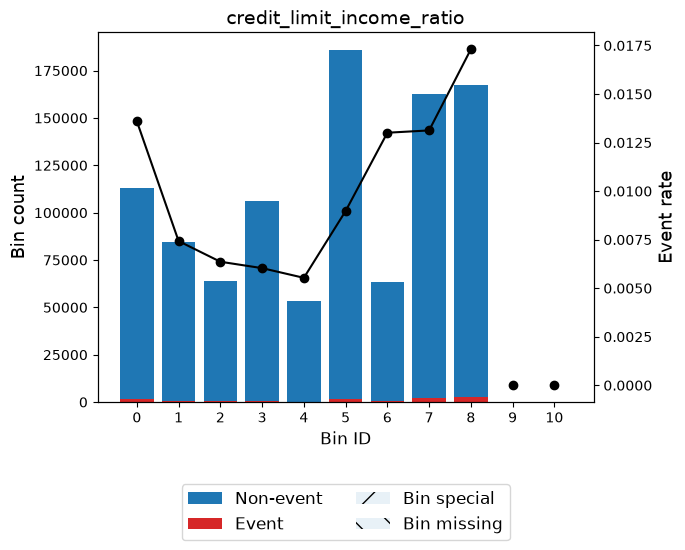

variable credit_risk_limit_ratio
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, 0.24)    51075     0.0511      49784   1291      0.0253 -0.8439 0.0563 0.0068
1       [0.24, 0.35)   137847     0.1378     134805   3042      0.0221 -0.7048 0.0983 0.0120
2       [0.35, 0.50)    61911     0.0619      61106    805      0.0130 -0.1666 0.0019 0.0002
3       [0.50, 0.88)   148725     0.1487     147271   1454      0.0098  0.1218 0.0021 0.0003
4       [0.88, 1.30)   258590     0.2586     256898   1692      0.0065  0.5266 0.0560 0.0069
5       [1.30, 1.42)   129570     0.1296     128766    804      0.0062  0.5800 0.0332 0.0041
6       [1.42, 1.47)    51619     0.0516      51334    285      0.0055  0.6975 0.0182 0.0022
7       [1.47, 1.54)    51023     0.0510      50693    330      0.0065  0.5383 0.0115 0.0014
8       [1.54, 1.67)    58140     0.0581      57629    511      0.0088  

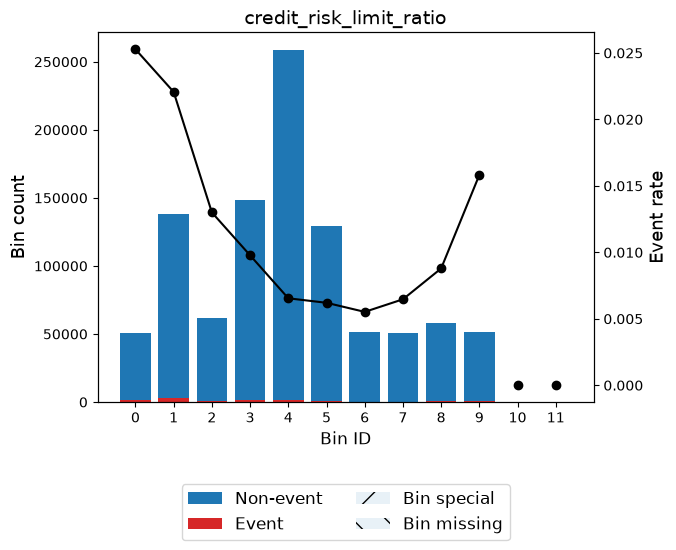

variable customer_stability_score
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0         (-inf, 8.50)    66937     0.0669      66674    263      0.0039  1.0393 0.0453 0.0054
1        [8.50, 15.50)    60552     0.0606      60325    227      0.0037  1.0864 0.0439 0.0052
2       [15.50, 25.50)    59568     0.0596      59382    186      0.0031  1.2699 0.0548 0.0064
3       [25.50, 37.50)   106400     0.1064     105937    463      0.0044  0.9367 0.0610 0.0074
4       [37.50, 46.50)    78733     0.0787      78287    446      0.0057  0.6717 0.0260 0.0032
5       [46.50, 55.50)    63302     0.0633      62695    607      0.0096  0.1414 0.0012 0.0001
6       [55.50, 64.50)    55833     0.0558      55202    631      0.0113 -0.0247 0.0000 0.0000
7       [64.50, 73.50)    51088     0.0511      50471    617      0.0121 -0.0919 0.0005 0.0001
8       [73.50, 90.50)    73181     0.0732      71972

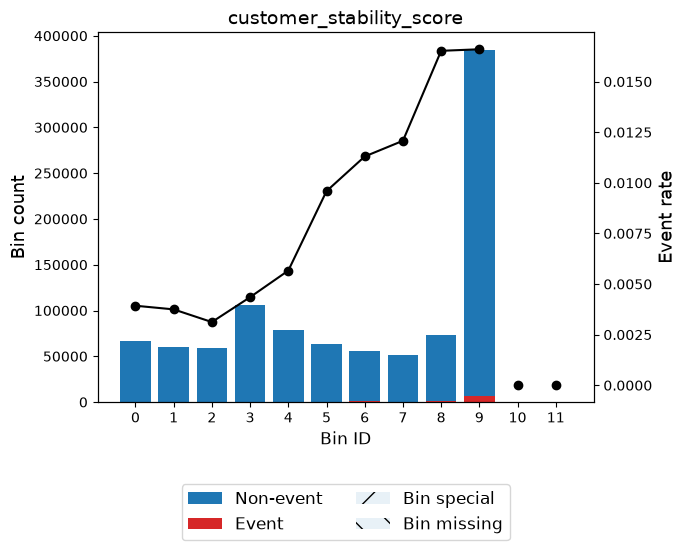

variable contact_consistency
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       (-inf, 0.50)   671015     0.6710     661748   9267      0.0138 -0.2277 0.0390 0.0049
1        [0.50, inf)   328985     0.3290     327223   1762      0.0054  0.7281 0.1246 0.0152
2            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
3            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.1635 0.0201


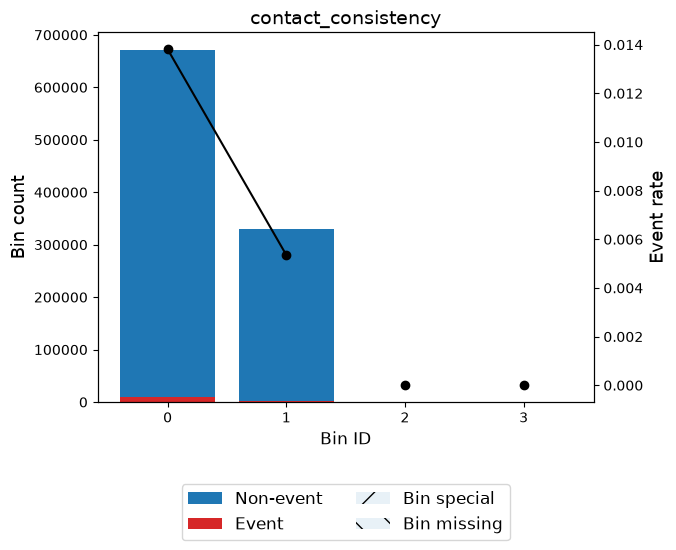

In [40]:
df_result = plot_analisis(
    df_numeric,
    "numerical",
    columnas_numericas,
    "target",
    0.09
)

In [41]:
df_result

,index,IV
0,address_stability_ratio,0.413615
1,customer_stability_score,0.329117
2,credit_risk_limit_ratio,0.288510
3,digital_identity_score,0.238047
4,device_trust_score,0.235418
5,address_total_history,0.167112
6,contact_consistency,0.163543
7,credit_limit_income_ratio,0.138893


# Análisis de correlaciones

## Pearson

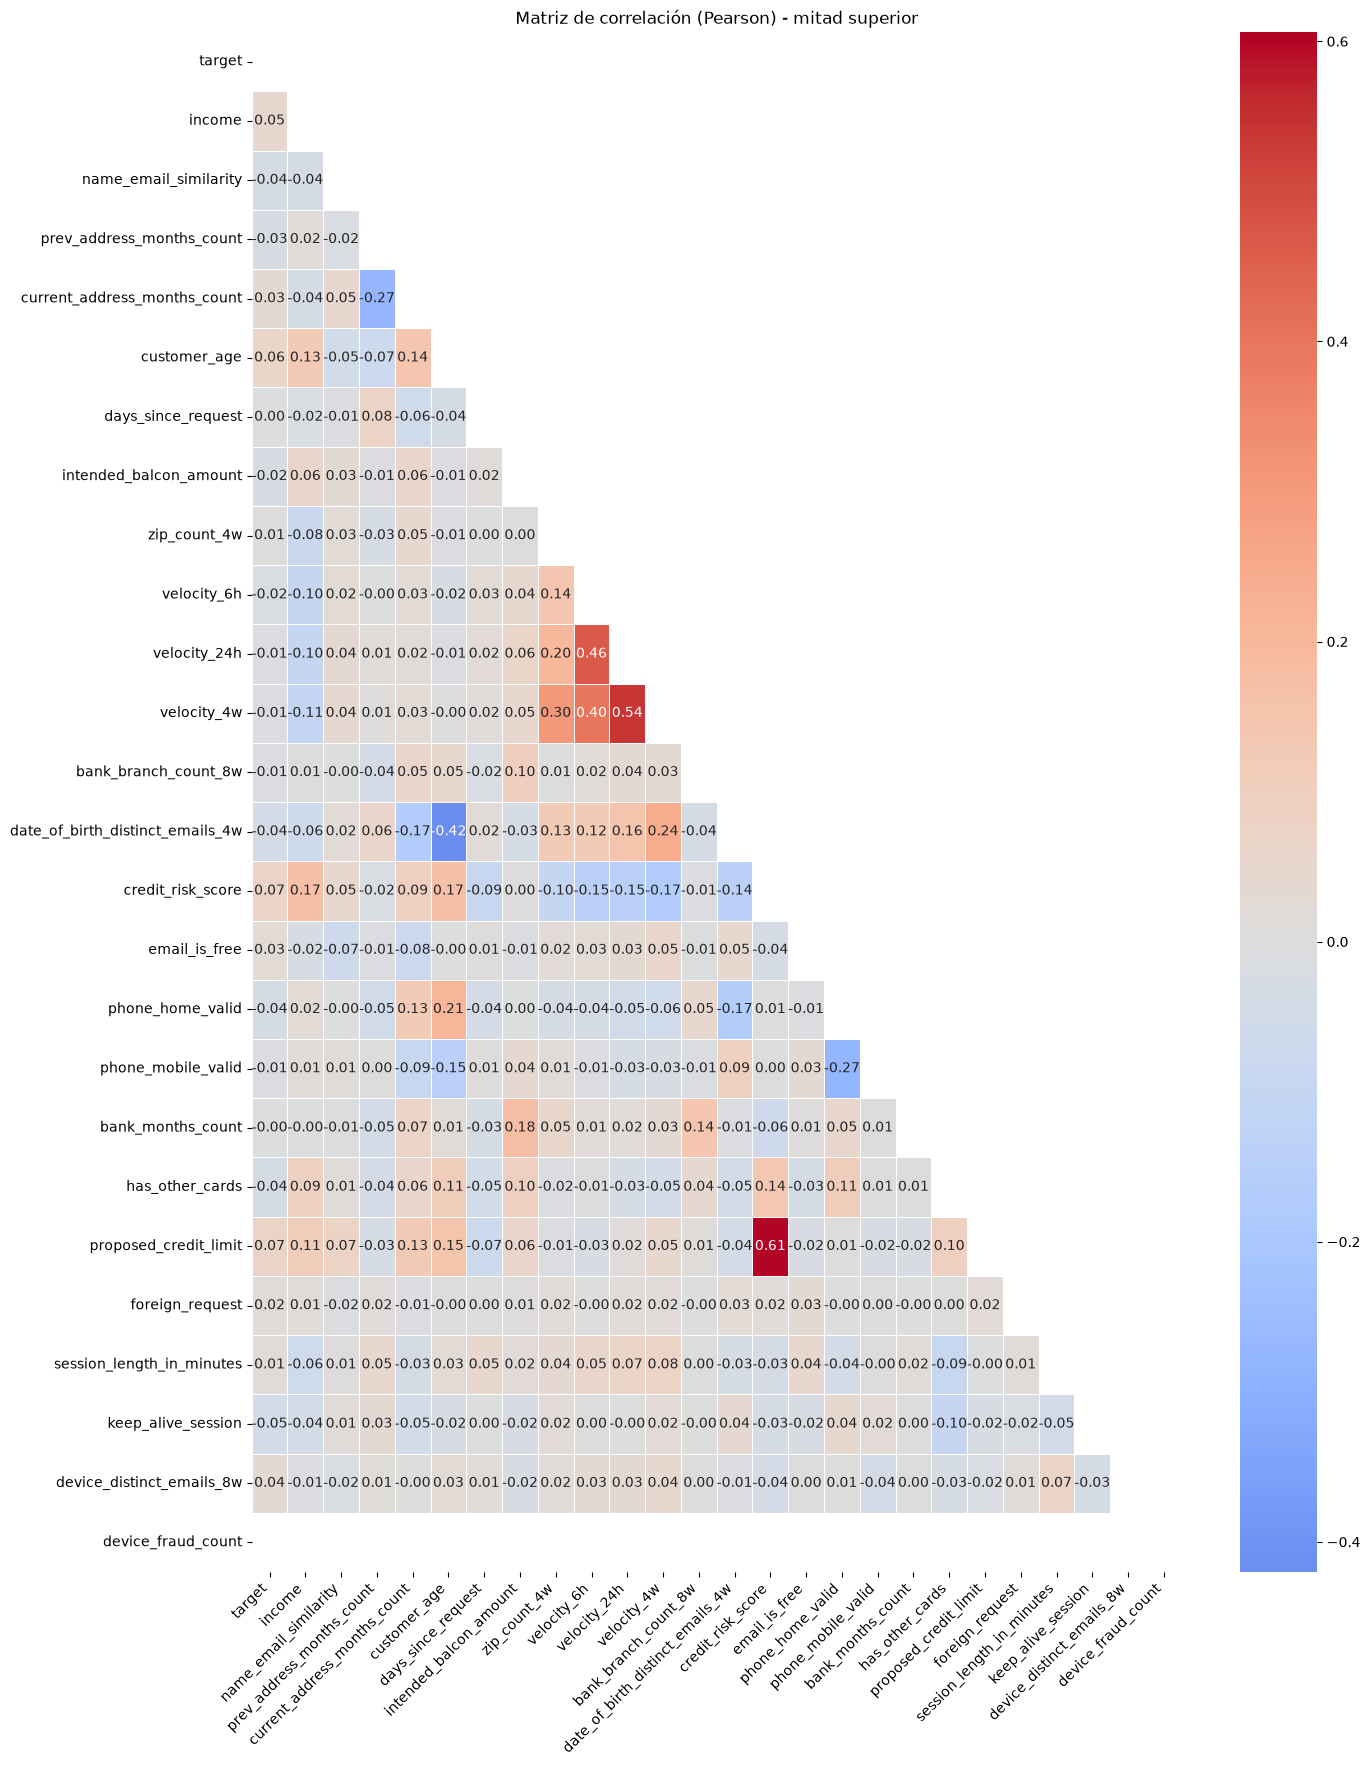

In [25]:
# Matriz de correlación de Pearson con el target incluido y mostrando solo la mitad superior
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    corr_matrix = numeric_df.corr(method='pearson')
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    corr_matrix = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))

    plt.figure(figsize=(15, 20))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f',
        linewidths=0.5
    )
    plt.title('Matriz de correlación (Pearson) - mitad superior')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


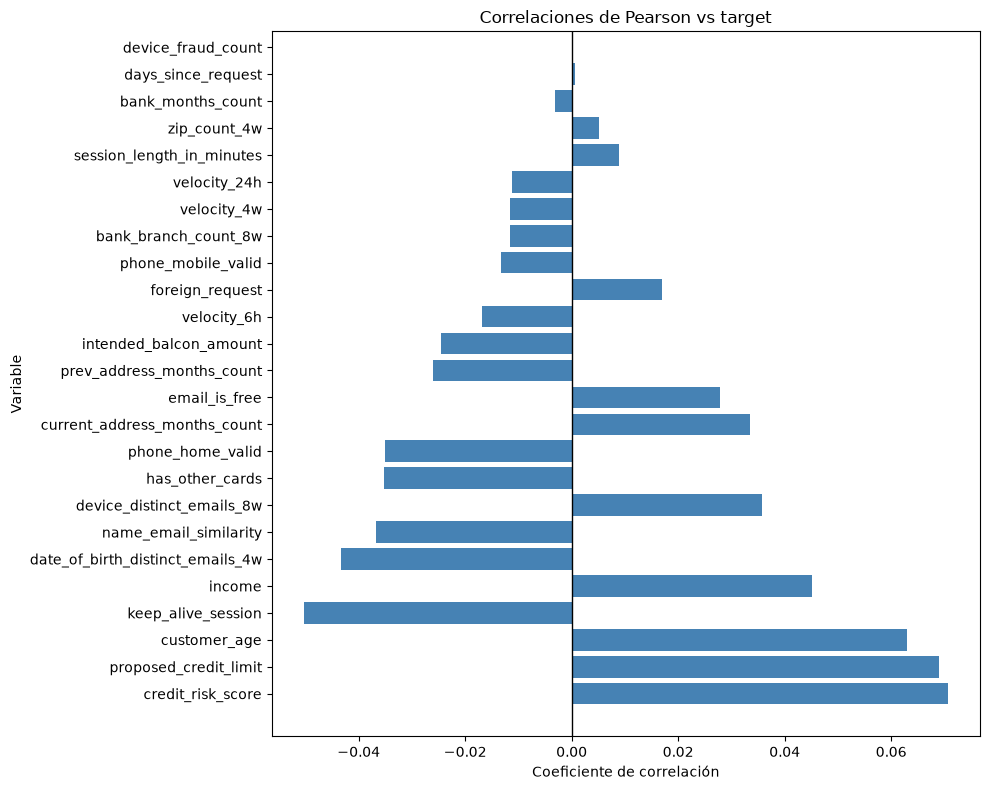

In [26]:
# Correlaciones de Pearson entre variables numéricas y el target
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    features = [col for col in numeric_df.columns if col != 'target']
    correlations = pd.DataFrame(
        {'correlacion': [numeric_df[col].corr(numeric_df['target'], method='pearson') for col in features]},
        index=features
    ).sort_values('correlacion', key=lambda x: x.abs(), ascending=False)

    plt.figure(figsize=(10, 8))
    plt.barh(correlations.index, correlations['correlacion'], color='steelblue')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Correlaciones de Pearson vs target')
    plt.xlabel('Coeficiente de correlación')
    plt.ylabel('Variable')
    plt.tight_layout()
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

### Semaforización

In [27]:
import numpy as np
import pandas as pd
from typing import Optional


# Función para mostrar 3 niveles de correlación
def categorizar_correlaciones(
    corr: pd.DataFrame,
    usar_abs: bool = True,
    imprimir: bool = True,
    top_por_categoria: Optional[int] = None
):

    mat = corr.abs() if usar_abs else corr.copy()

    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1)
    pares = mat.where(mask).stack().reset_index()
    pares.columns = ["var_1", "var_2", "corr"]

    pares["corr_pct"] = pares["corr"] * 100

    bins = [-0.0000001, 10, 60, 100]
    labels = ["Aceptable", "Medio", "Alto"]

    pares["categoria"] = pd.cut(
        pares["corr_pct"],
        bins=bins,
        labels=labels,
        right=True
    )

    pares = pares.sort_values(
        "corr",
        ascending=False
    ).reset_index(drop=True)

    salida = {}

    for cat in ["Alto", "Medio", "Aceptable"]:

        df_cat = pares.loc[
            pares["categoria"] == cat,
            ["var_1", "var_2", "corr", "corr_pct"]
        ].copy()

        df_cat["corr_pct"] = df_cat["corr_pct"].round(2)

        if top_por_categoria is not None:
            df_cat = df_cat.head(top_por_categoria)

        salida[cat] = df_cat

    if imprimir:

        signo = "|corr|" if usar_abs else "corr"

        print(f"\n=== Clasificación por {signo} (pares únicos, sin duplicados) ===")

        for cat in ["Alto", "Medio", "Aceptable"]:

            df_cat = salida[cat]

            print(f"\n--- {cat} ({len(df_cat)} pares) ---")

            if df_cat.empty:
                print("No hay pares en esta categoría.")

            else:

                for _, r in df_cat.iterrows():
                    print(
                        f"{r['var_1']} vs {r['var_2']}: {r['corr_pct']}%"
                    )

    return salida

In [28]:
df_num = df_data.select_dtypes(include=[np.number])
df_corr = df_num.corr(method='pearson')

#salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True, top_por_categoria=5)
salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)


=== Clasificación por |corr| (pares únicos, sin duplicados) ===

--- Alto (1 pares) ---
credit_risk_score vs proposed_credit_limit: 60.61%

--- Medio (38 pares) ---
velocity_24h vs velocity_4w: 53.91%
velocity_6h vs velocity_24h: 46.4%
customer_age vs date_of_birth_distinct_emails_4w: 42.02%
velocity_6h vs velocity_4w: 40.03%
zip_count_4w vs velocity_4w: 30.3%
phone_home_valid vs phone_mobile_valid: 27.24%
prev_address_months_count vs current_address_months_count: 27.02%
velocity_4w vs date_of_birth_distinct_emails_4w: 24.24%
customer_age vs phone_home_valid: 21.27%
zip_count_4w vs velocity_24h: 20.12%
intended_balcon_amount vs bank_months_count: 17.84%
current_address_months_count vs date_of_birth_distinct_emails_4w: 17.45%
income vs credit_risk_score: 17.14%
velocity_4w vs credit_risk_score: 16.88%
date_of_birth_distinct_emails_4w vs phone_home_valid: 16.66%
customer_age vs credit_risk_score: 16.61%
velocity_24h vs date_of_birth_distinct_emails_4w: 15.54%
customer_age vs proposed_cr

In [29]:
from IPython.display import display

for categoria, df in salida.items():
    print(f"\n===== {categoria} ({len(df)} pares) =====")
    display(df)


===== Alto (1 pares) =====


,var_1,var_2,corr,corr_pct
0,credit_risk_score,proposed_credit_limit,0.606141,60.61



===== Medio (38 pares) =====


,var_1,var_2,corr,corr_pct
1,velocity_24h,velocity_4w,0.539115,53.91
2,velocity_6h,velocity_24h,0.464003,46.40
3,customer_age,date_of_birth_distinct_emails_4w,0.420173,42.02
4,velocity_6h,velocity_4w,0.400254,40.03
5,zip_count_4w,velocity_4w,0.302955,30.30
6,phone_home_valid,phone_mobile_valid,0.272392,27.24
7,prev_address_months_count,current_address_months_count,0.270199,27.02
8,velocity_4w,date_of_birth_distinct_emails_4w,0.242365,24.24
9,customer_age,phone_home_valid,0.212713,21.27
10,zip_count_4w,velocity_24h,0.201186,20.12



===== Aceptable (261 pares) =====


,var_1,var_2,corr,corr_pct
39,has_other_cards,keep_alive_session,0.098102,9.81
40,intended_balcon_amount,has_other_cards,0.096676,9.67
41,income,velocity_6h,0.096431,9.64
42,has_other_cards,proposed_credit_limit,0.096254,9.63
43,current_address_months_count,credit_risk_score,0.094876,9.49
44,date_of_birth_distinct_emails_4w,phone_mobile_valid,0.093366,9.34
45,has_other_cards,session_length_in_minutes,0.092723,9.27
46,days_since_request,credit_risk_score,0.088141,8.81
47,current_address_months_count,phone_mobile_valid,0.088076,8.81
48,income,has_other_cards,0.086861,8.69


### Multicolinealidad

Pearson r (credit_risk_score, proposed_credit_limit) = 0.606


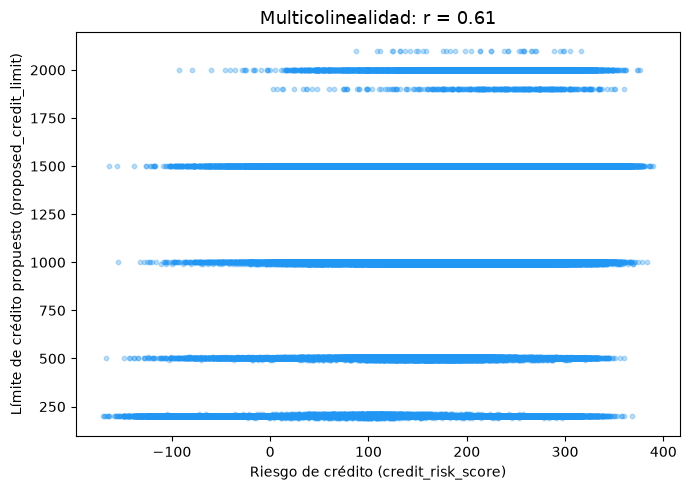

In [ ]:
r = df_data["credit_risk_score"].corr(df_data["proposed_credit_limit"])
print(f"Pearson r (credit_risk_score, proposed_credit_limit) = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_data["credit_risk_score"], df_data["proposed_credit_limit"],
           alpha=0.3, s=10, color="#2196F3")
ax.set_xlabel("Riesgo de crédito (credit_risk_score)")
ax.set_ylabel("Límite de crédito propuesto (proposed_credit_limit)")
ax.set_title(f"Multicolinealidad: r = {r:.2f}", fontsize=13)
plt.tight_layout()
plt.show()

Pearson r (velocity_24h, velocity_4w) = 0.539


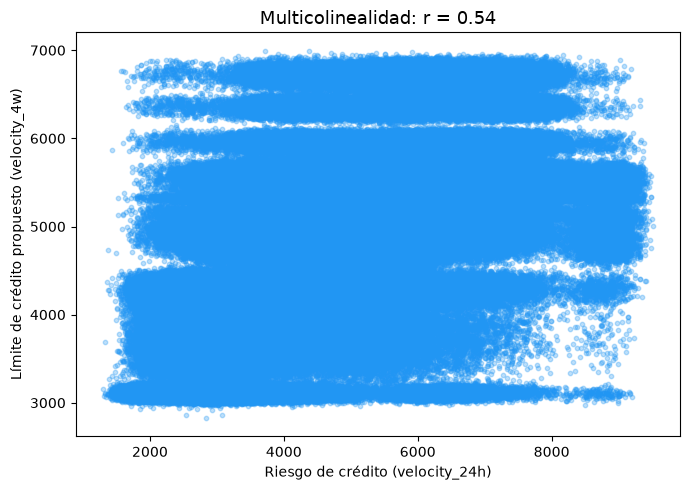

In [31]:
r = df_data["velocity_24h"].corr(df_data["velocity_4w"])
print(f"Pearson r (velocity_24h, velocity_4w) = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_data["velocity_24h"], df_data["velocity_4w"],
           alpha=0.3, s=10, color="#2196F3")
ax.set_xlabel("Riesgo de crédito (velocity_24h)")
ax.set_ylabel("Límite de crédito propuesto (velocity_4w)")
ax.set_title(f"Multicolinealidad: r = {r:.2f}", fontsize=13)
plt.tight_layout()
plt.show()


# Pairplot de variables seleccionadas

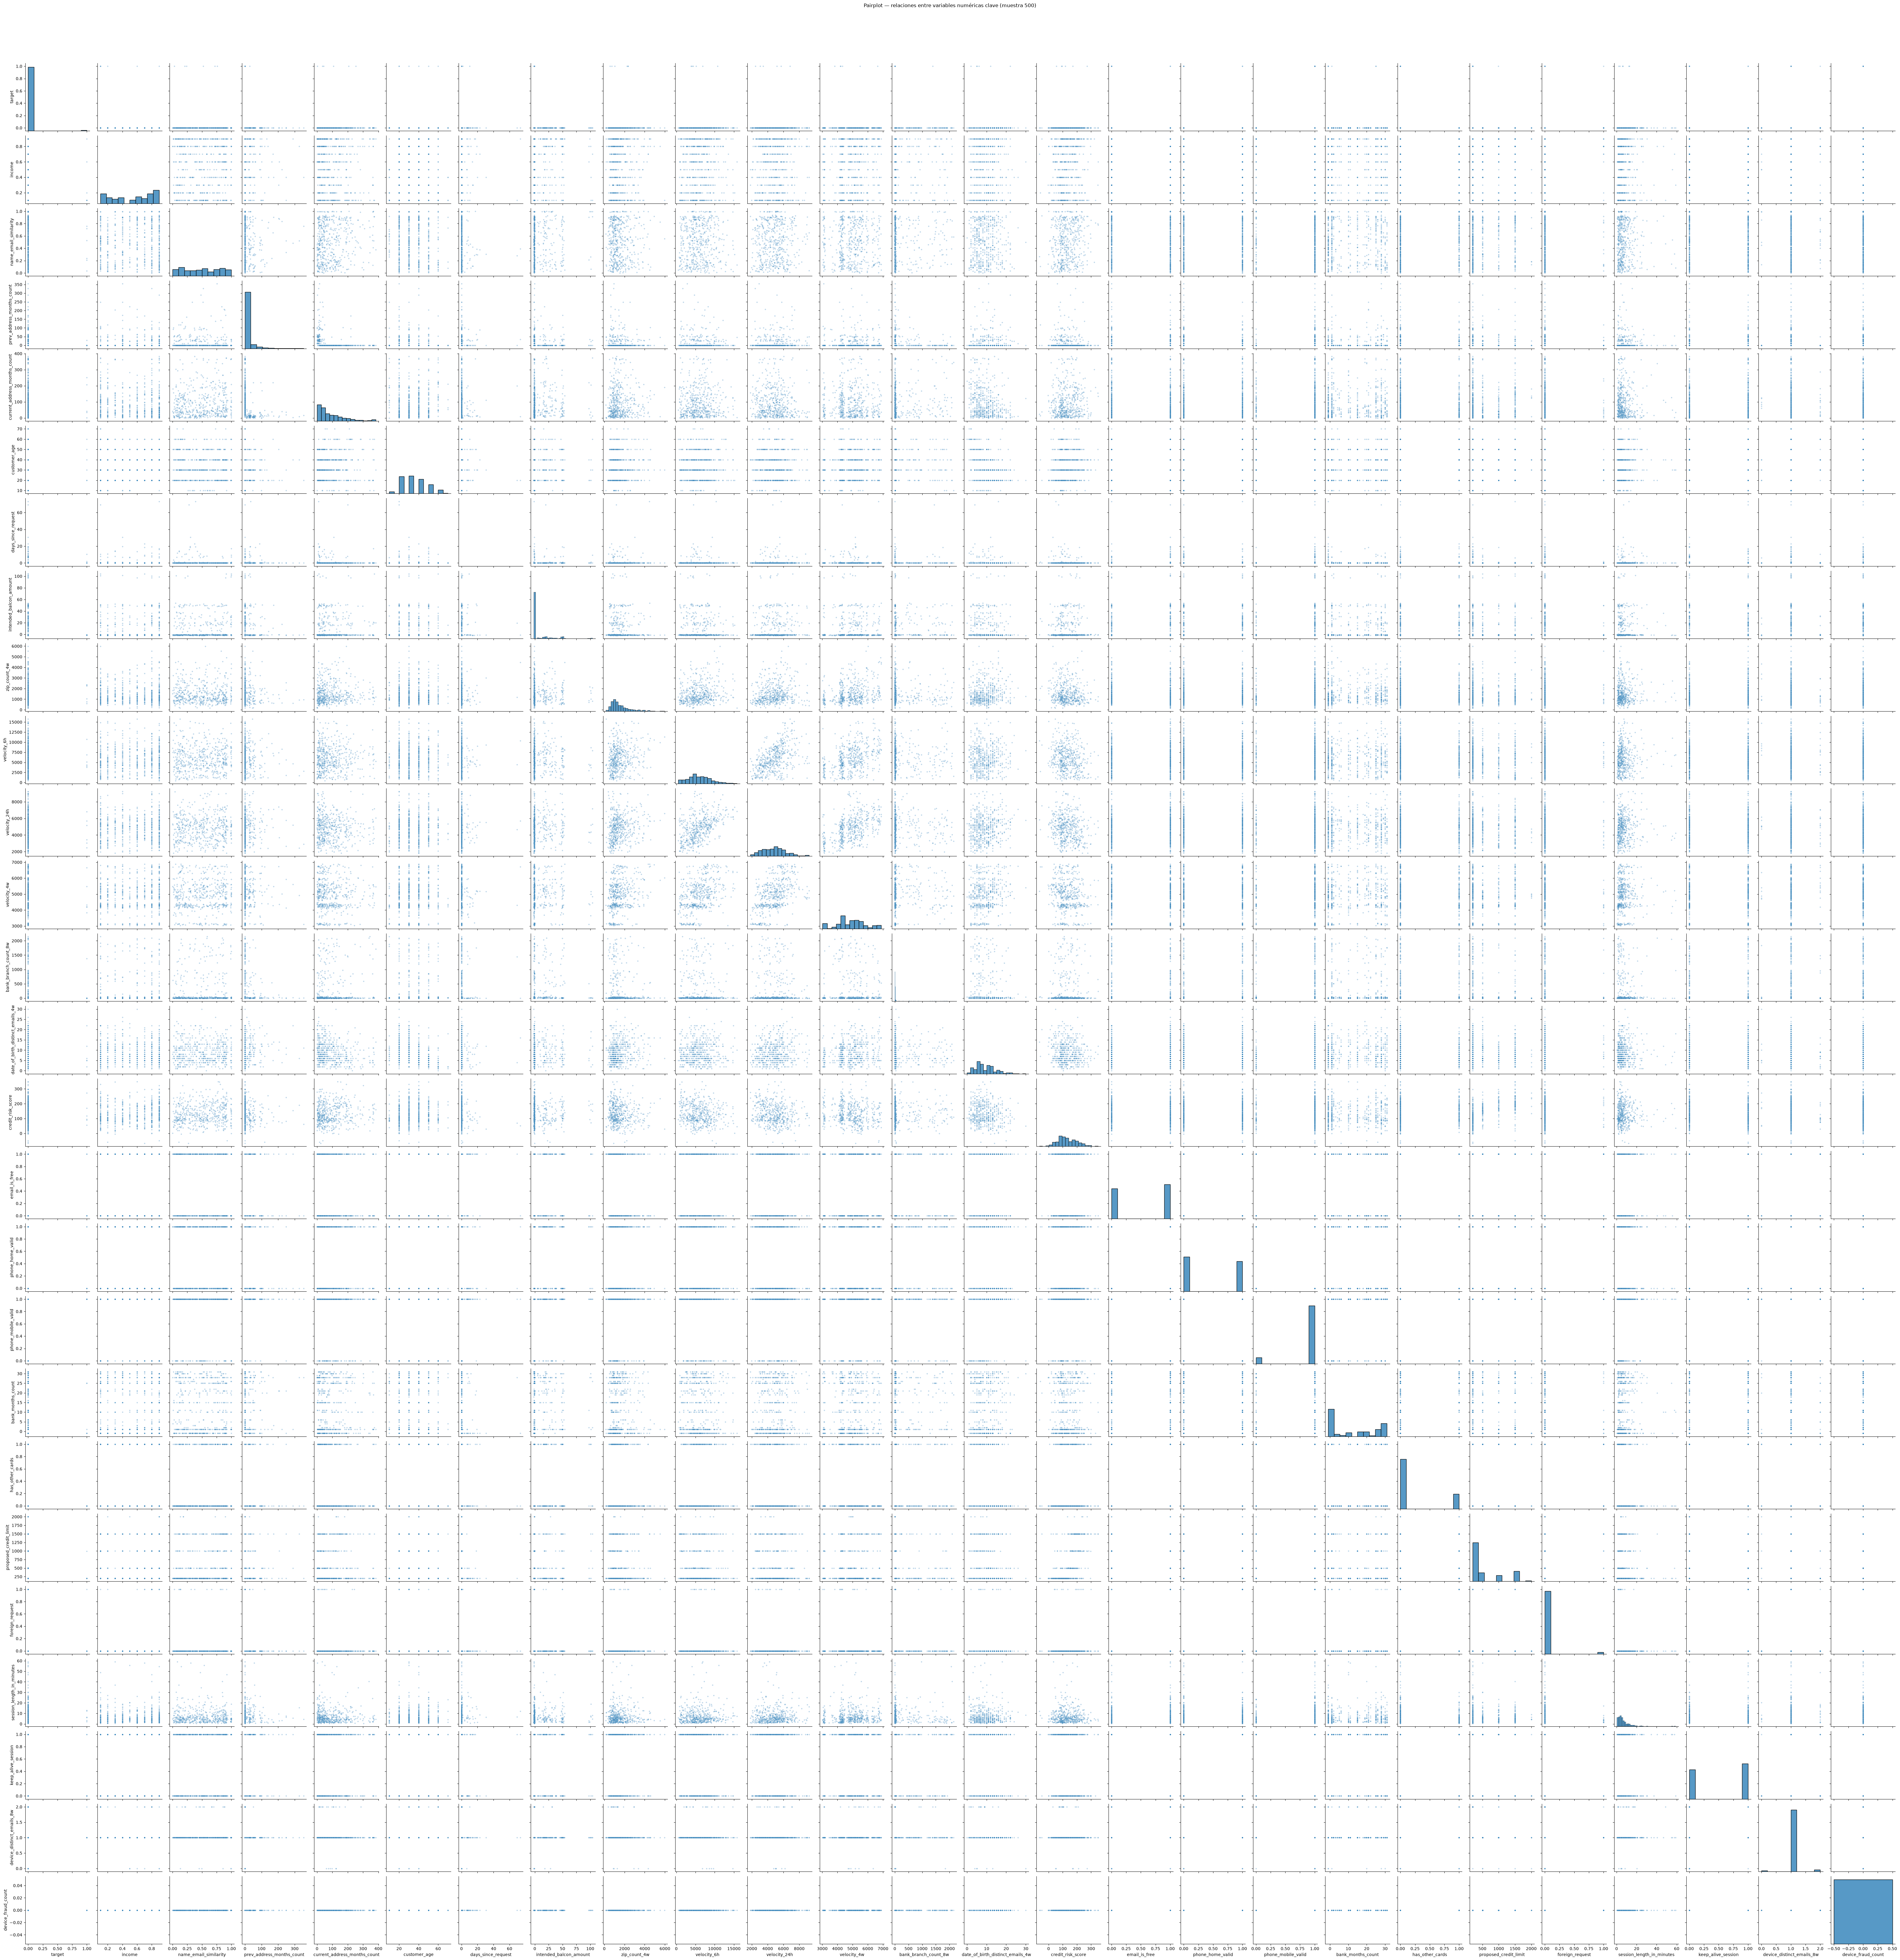

In [32]:
pairplot_cols = df_data.select_dtypes(include=[np.number]).columns.tolist()

g = sns.pairplot(df_data[pairplot_cols].sample(500, random_state=42),
                 diag_kind="hist", plot_kws={"alpha": 0.3, "s": 10})
g.figure.suptitle("Pairplot — relaciones entre variables numéricas clave (muestra 500)", y=1.02)
plt.show()

Coeficiente de asimetría (skewness): 0.30
(> 1.0 indica asimetría derecha moderada-alta)


c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


ValueError: supplied range of [-inf, 5.966146739123692] is not finite

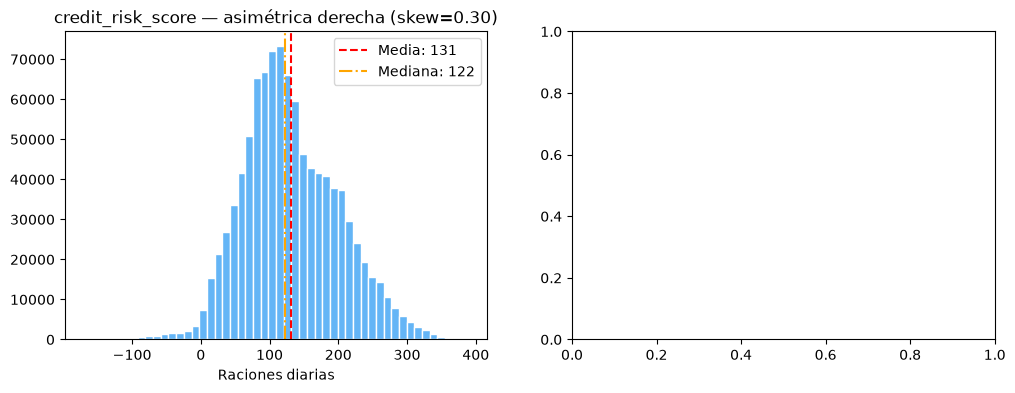

In [34]:
skewness = df_data["credit_risk_score"].skew()
print(f"Coeficiente de asimetría (skewness): {skewness:.2f}")
print("(> 1.0 indica asimetría derecha moderada-alta)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df_data["credit_risk_score"], bins=50, color="#64B5F6", edgecolor="white")
ax1.axvline(df_data["credit_risk_score"].mean(), color="red", linestyle="--",
            label=f"Media: {df_data['credit_risk_score'].mean():.0f}")
ax1.axvline(df_data["credit_risk_score"].median(), color="orange", linestyle="-.",
            label=f"Mediana: {df_data['credit_risk_score'].median():.0f}")
ax1.set_title(f"credit_risk_score — asimétrica derecha (skew={skewness:.2f})", fontsize=12)
ax1.set_xlabel("Raciones diarias")
ax1.legend()

log_meals = np.log1p(df_data["credit_risk_score"])
ax2.hist(log_meals, bins=50, color="#A5D6A7", edgecolor="white")
ax2.set_title("log1p(credit_risk_score) — distribución más simétrica", fontsize=12)
ax2.set_xlabel("log(1 + raciones diarias)")

plt.tight_layout()
plt.show()
